# Univariate Time Series Analysis

In this notebook we will analyze temporal aspects of our data for different variables.

Our objective is answering the following questions:

1. What do we observe when we visualize the time-series of each variable?

2. What is the mean and variance of each variable and how much of the variance is explained by pig-level differences or pen-level differences?
3. Is the variability of each variable stable over time, or does it change with age or with the level of the series (heteroscedasticity)?
4. Which variables have trend, stationarity, seasonality and age-dependence
5. Are observations of each variables dependent on previous observations? How much memory do they have (ACF/PACF)
6. Which time series could present discontinuity
7. Do the series of different pigs/pens share common temporal patterns (farm-wide day effects, synchrony) or does each one evolve independently?

The analysis will be usefull to make the following decissions:

1. Which reference is used to compare each variable?

2. Do we need to apply transformations to the time-series

3. How can we treat discontinuity in temporal data?

## Preeliminaries: Loading the dataset

In [1]:
import pandas as pd
import numpy as np

In [2]:
PATH = "C:/Users/ericp/Desktop/PigLF/PigLF-health-forecast/data/raw/Batch4_PigLF_animal_dia.csv"   # Change depending on your file location

df = pd.read_csv(PATH, parse_dates=["Date"])

df.head()

,Date,Fattening_day,Week,Animal_ID,Pen,Feed_intake_kg,Number_visits,Duration_min,Feeding_rate_g_min,Body_weight_kg,ADG_kg_d,FCR,RFI_kg_d,Water_use_L,Respiratory_score,Incidencias,Incidencias_tipo,Water_use_pen_L,Animals_in_pen,Reliable_day
0,2026-05-18,1,1,182617,1,0.717,12.0,47.35,16.77,26.25,0.583,1.630,-0.477,2.55,33,0,NaN,28.0,11,False
1,2026-05-19,2,1,182617,1,0.903,21.0,53.50,21.91,26.36,0.548,1.758,-0.463,3.27,38,0,NaN,36.0,11,True
2,2026-05-20,3,1,182617,1,1.098,12.0,59.40,41.82,27.00,0.375,2.527,-0.445,4.18,54,0,NaN,46.0,11,True
3,2026-05-21,4,1,182617,1,1.086,15.0,61.43,17.71,27.82,0.508,1.975,-0.422,4.18,38,0,NaN,46.0,11,True
4,2026-05-22,5,1,182617,1,1.009,15.0,62.05,14.98,28.14,0.595,1.819,-0.367,4.27,53,0,NaN,47.0,11,True


## 1. Time-series visualization

### Room-level variables: Respiratory score

In [3]:
import sys
sys.path.append("../src")

from utils import plot_time_series, is_pen_level, plot_2D_grid

<Axes: title={'center': 'Daily Respiratory Score'}, xlabel='Date', ylabel='Respiratory_score'>

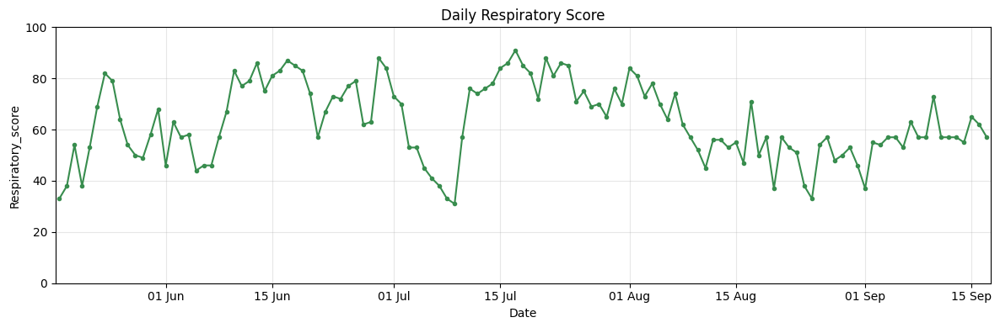

In [4]:
rs = df[df["Animal_ID"] == 182617].set_index("Date")["Respiratory_score"]

plot_time_series(rs.index, rs, title="Daily Respiratory Score",
                 color="#388D4E", ylim=(0, 100))

### Pen-level variables: Water use and animals in pen

#### Water use

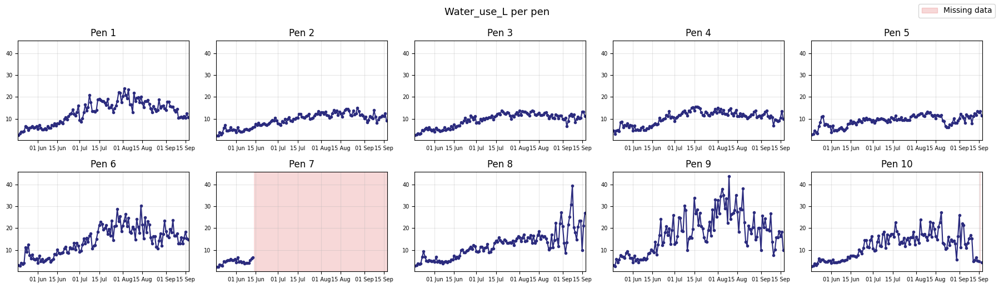

In [5]:
figs = plot_2D_grid(df, "Water_use_L", color="#2B2B7E")   


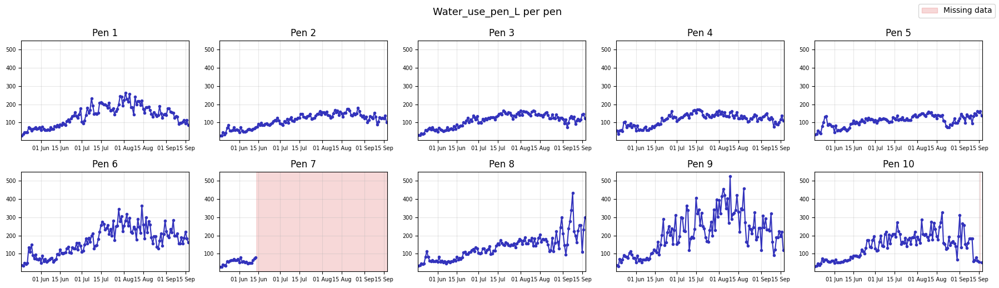

In [6]:
figs = plot_2D_grid(df, "Water_use_pen_L", color="#3333BC")   

Note that both variables look the same! This could suggest that one of the variables is proportional to the other. We will explore the relation later on

As we discussed in the first notebook, pen 7 water sensor could have failed for a prolonged time. Pens 6, 8, 9 appear to have higher water water consumption at some points.

#### Animals in pen

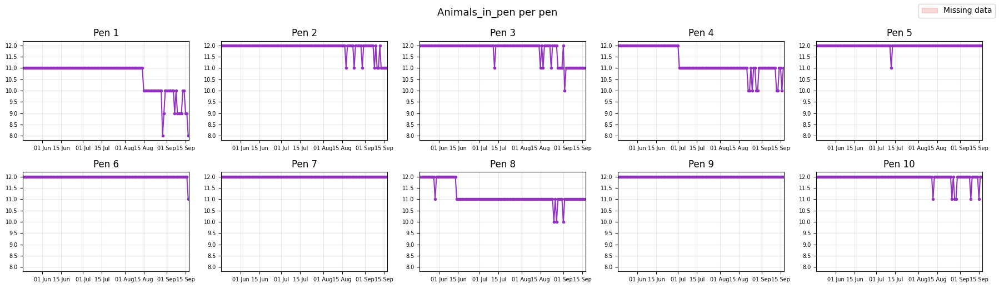

In [7]:
figs = plot_2D_grid(df, "Animals_in_pen", color="#9133BC")   

The non-constant graphs indicate that a pig has been temporally removed or withdrawn

### Pig-level variables: Feeding behavour

For more information, unfold the cells below

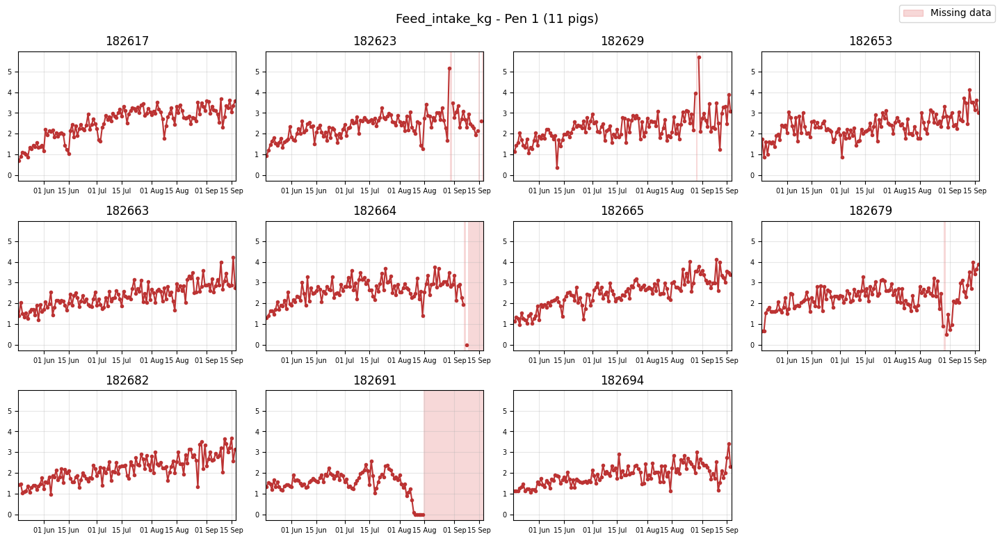

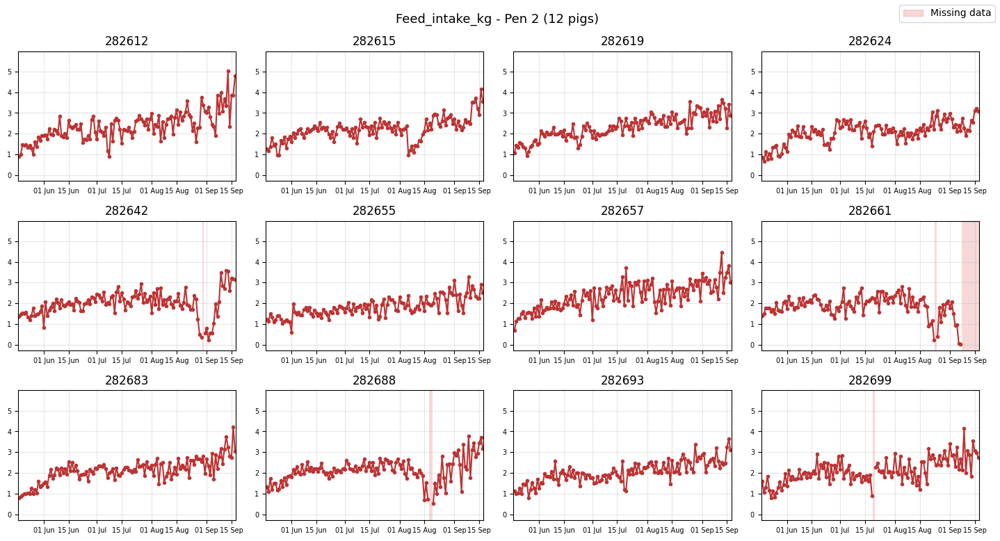

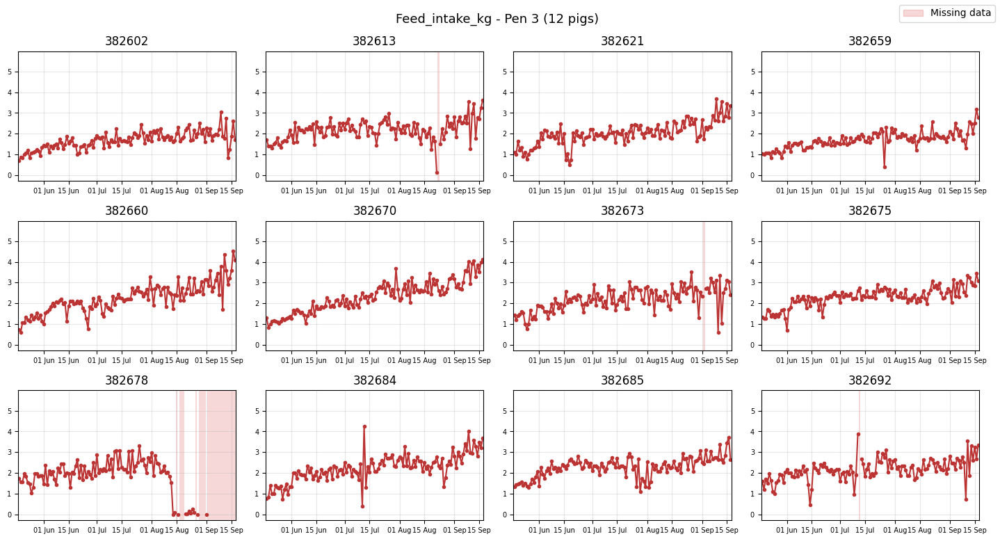

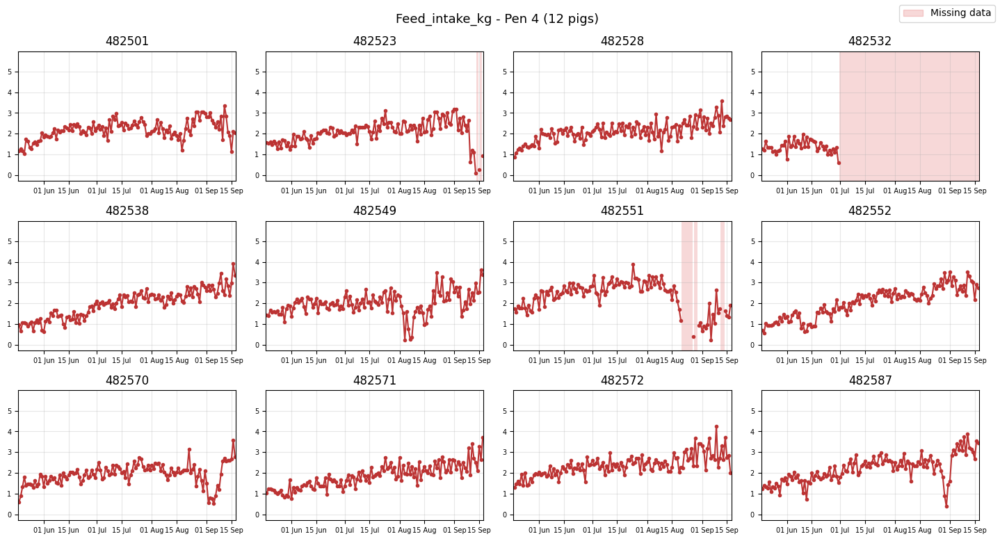

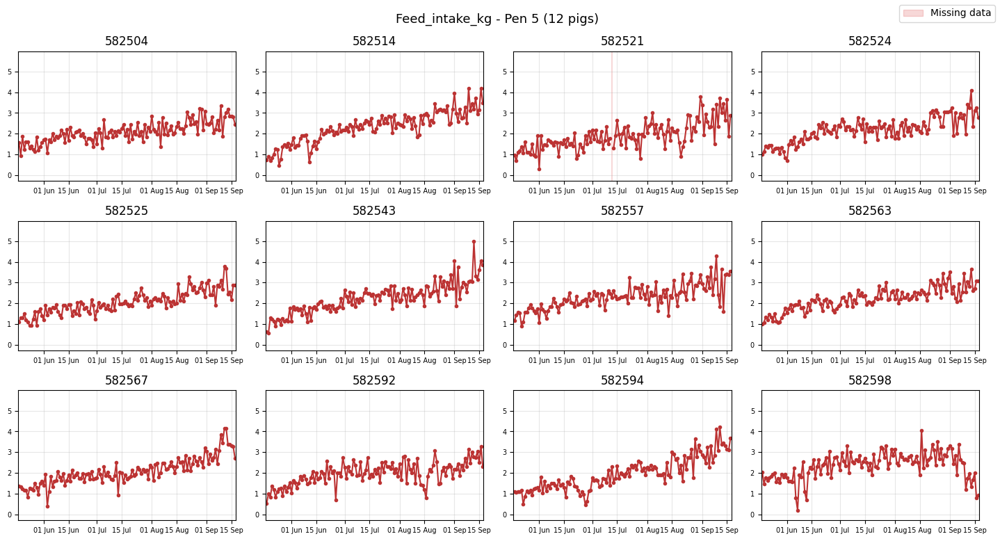

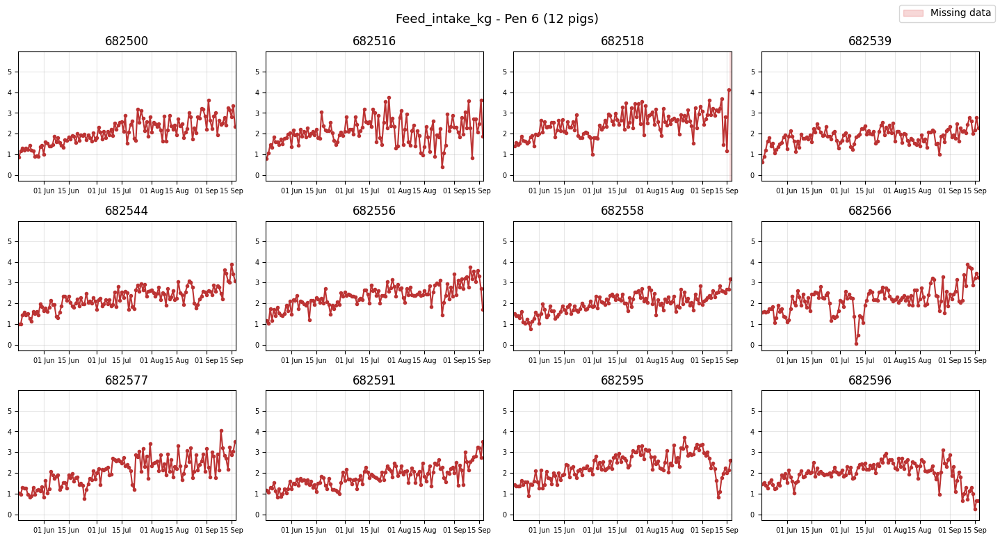

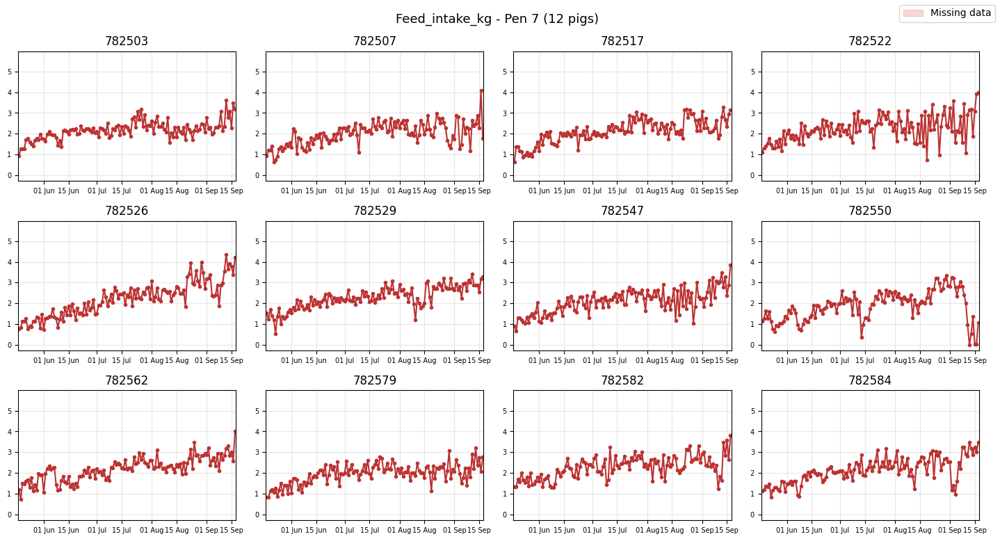

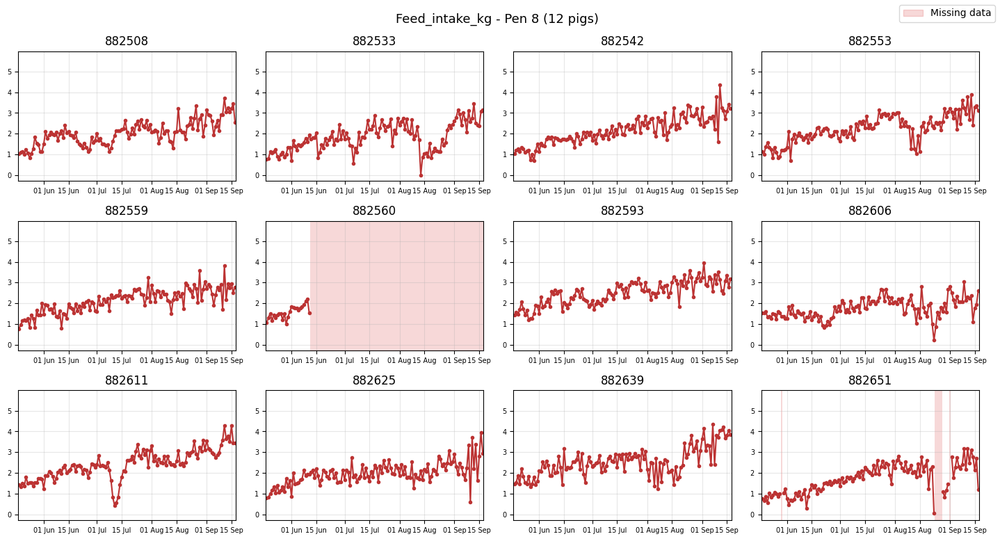

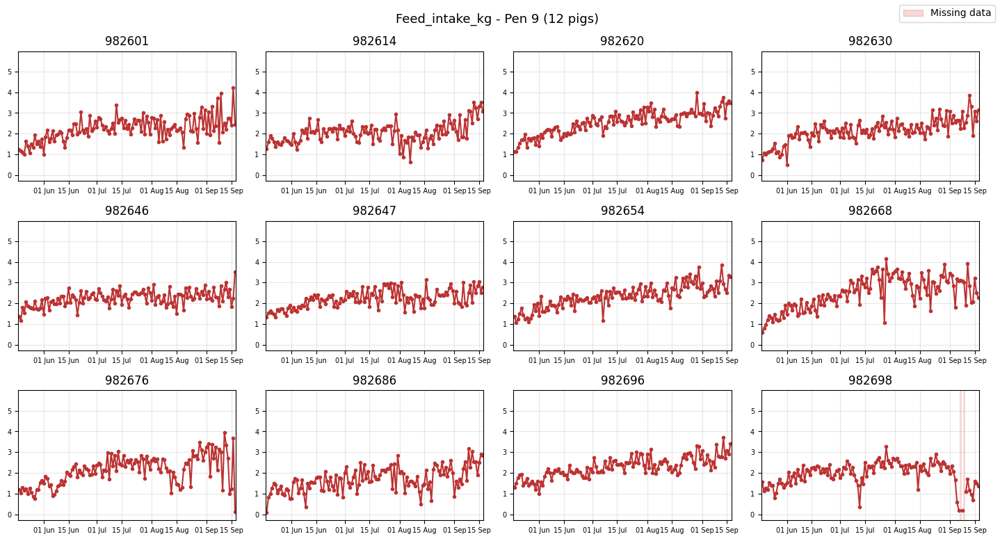

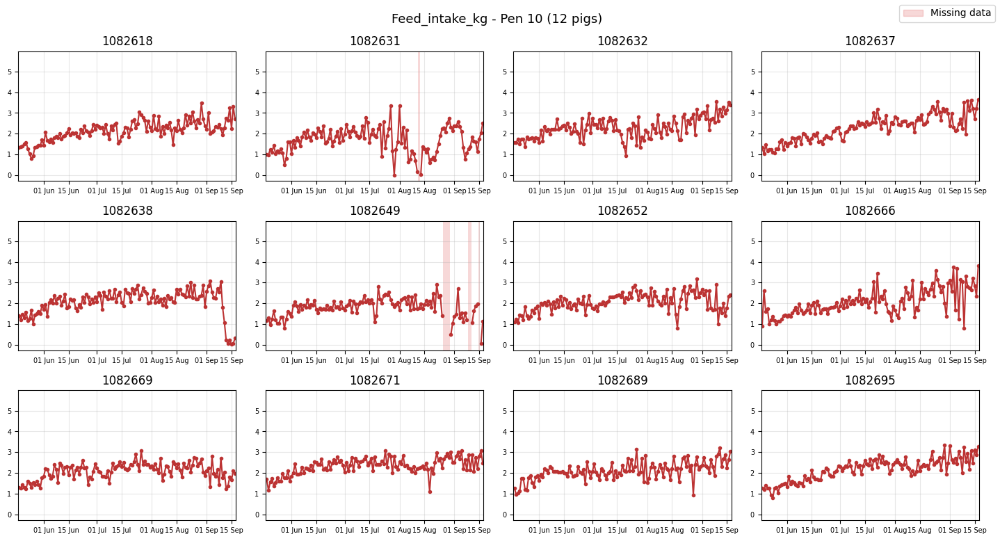

In [8]:
figs = plot_2D_grid(df, "Feed_intake_kg", color="#BC3333")   

Most pigs appear to have a positive trend in feed intake. In some cases, the intake falls in some intervals, which could be an indicator of an incidence.

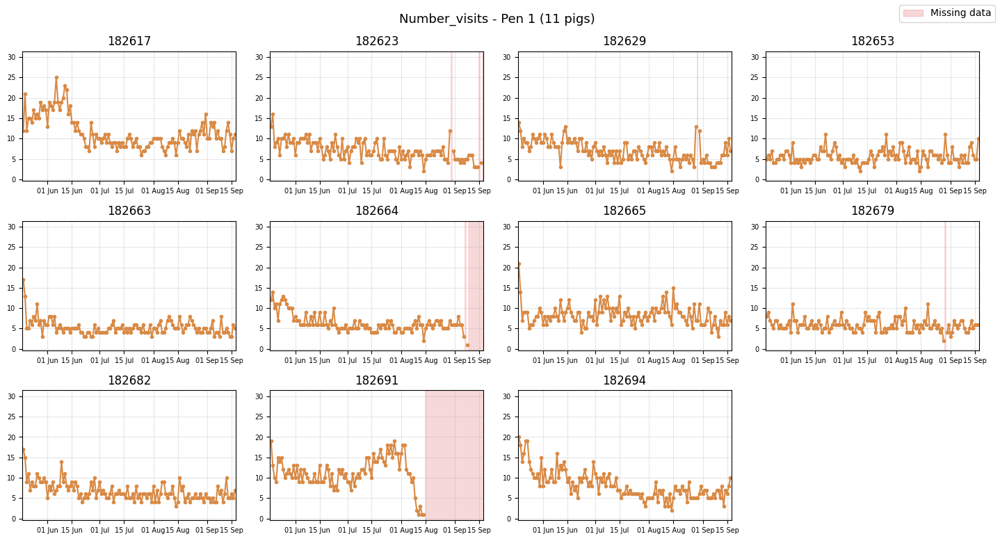

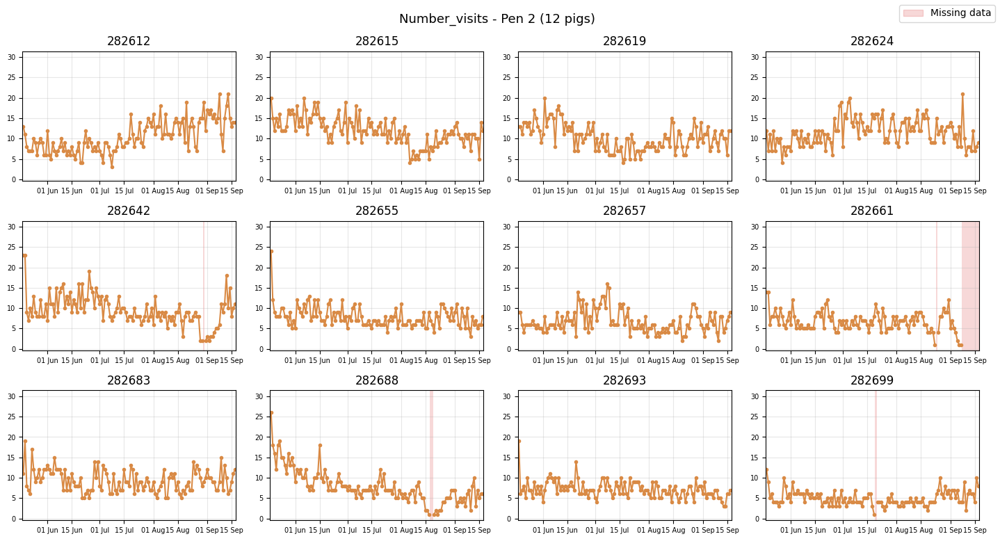

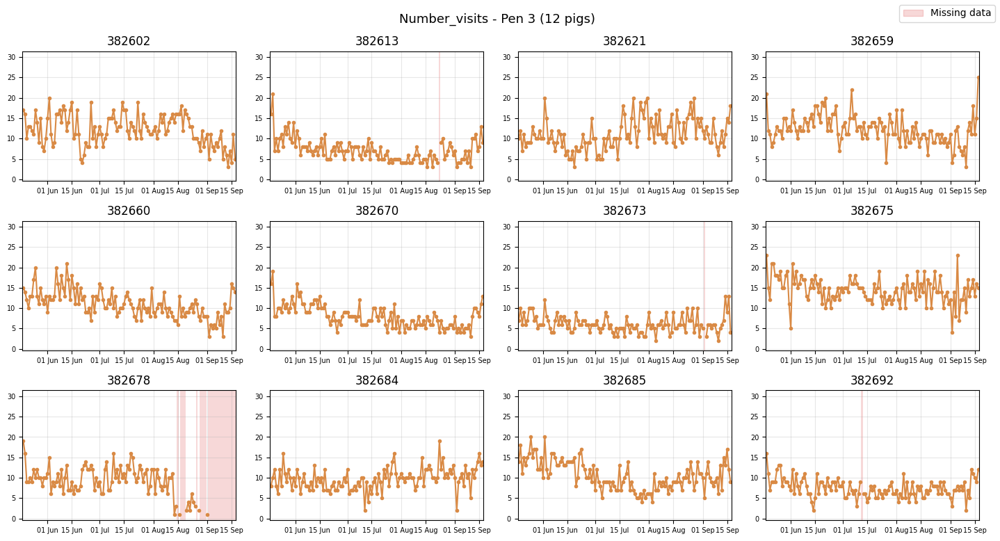

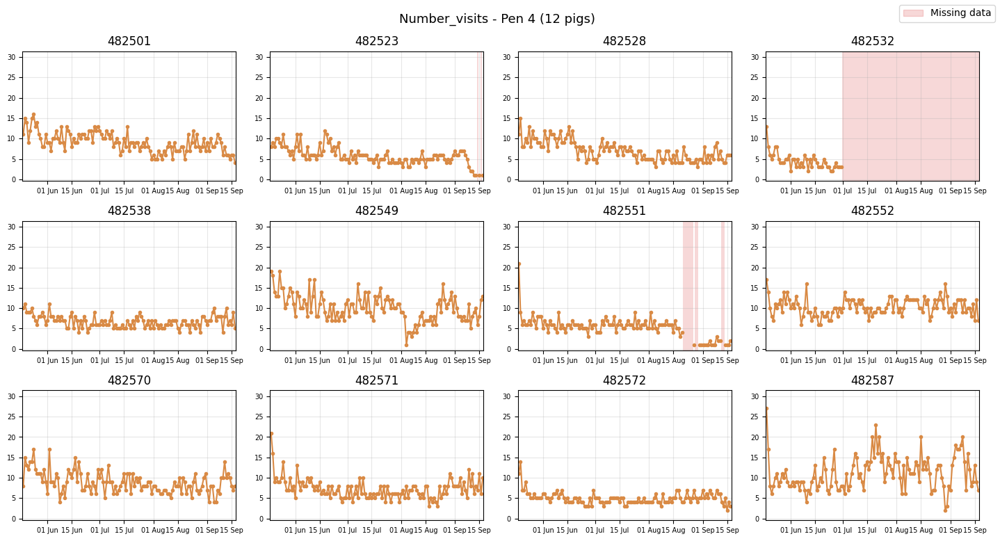

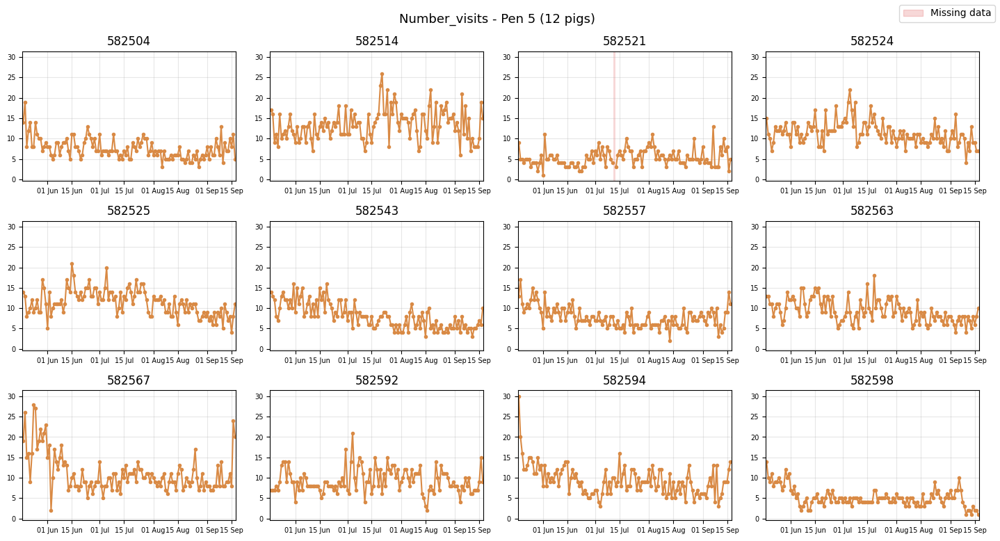

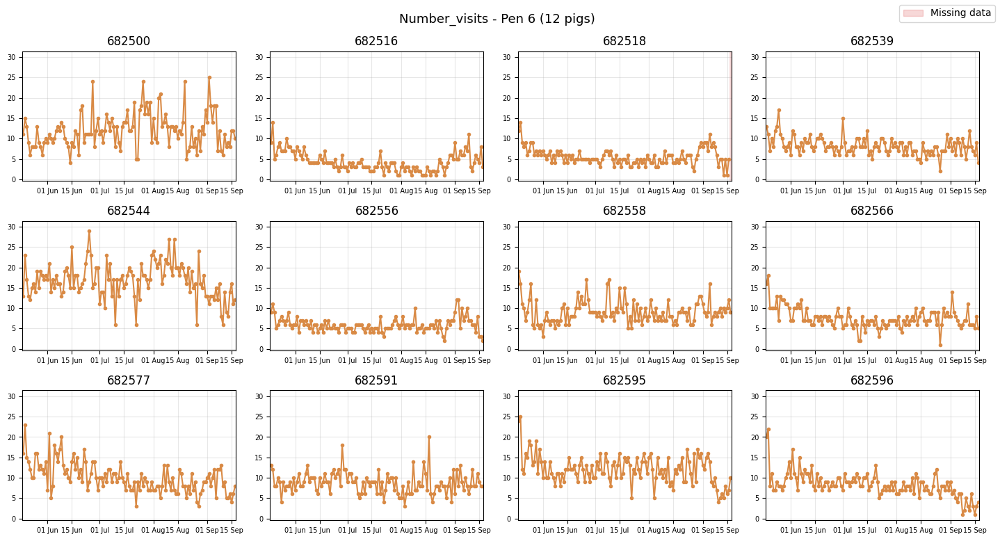

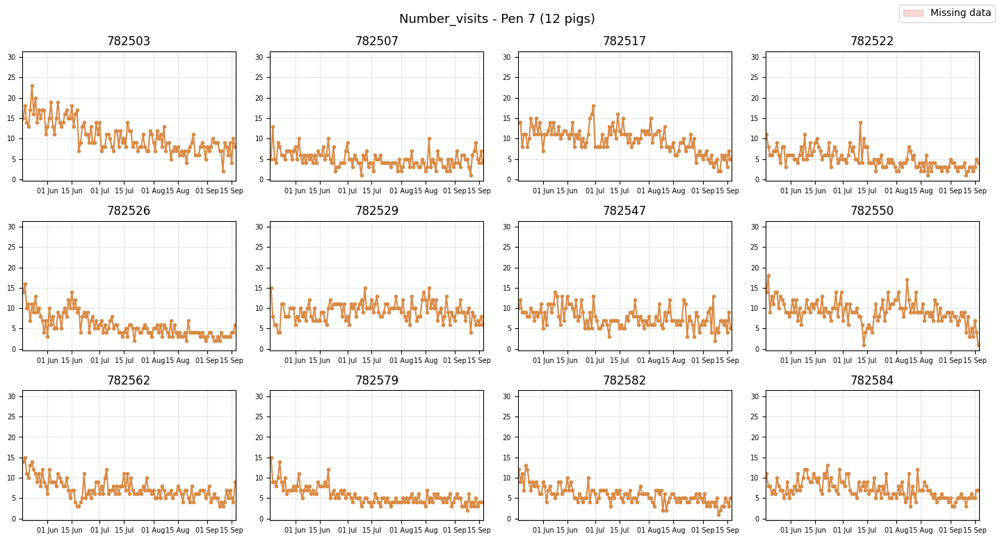

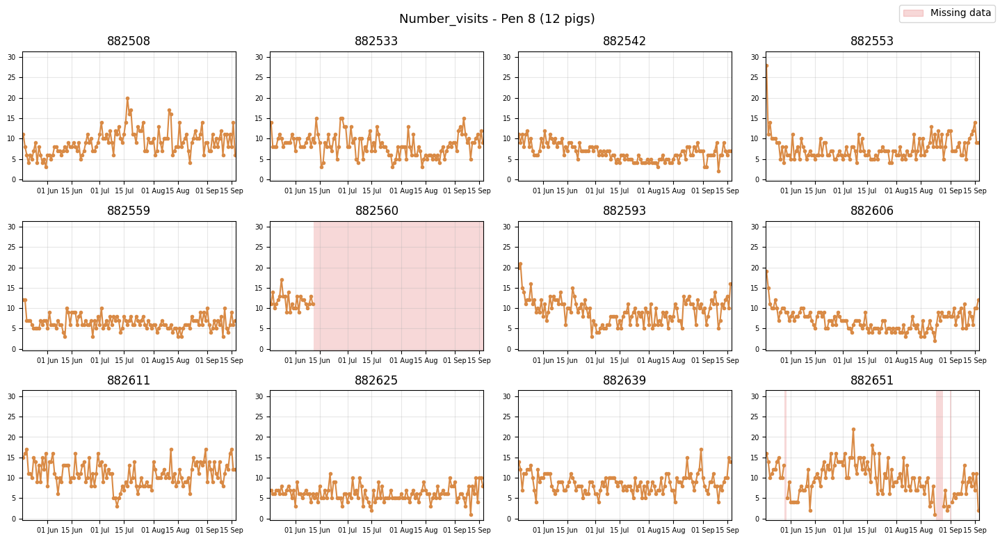

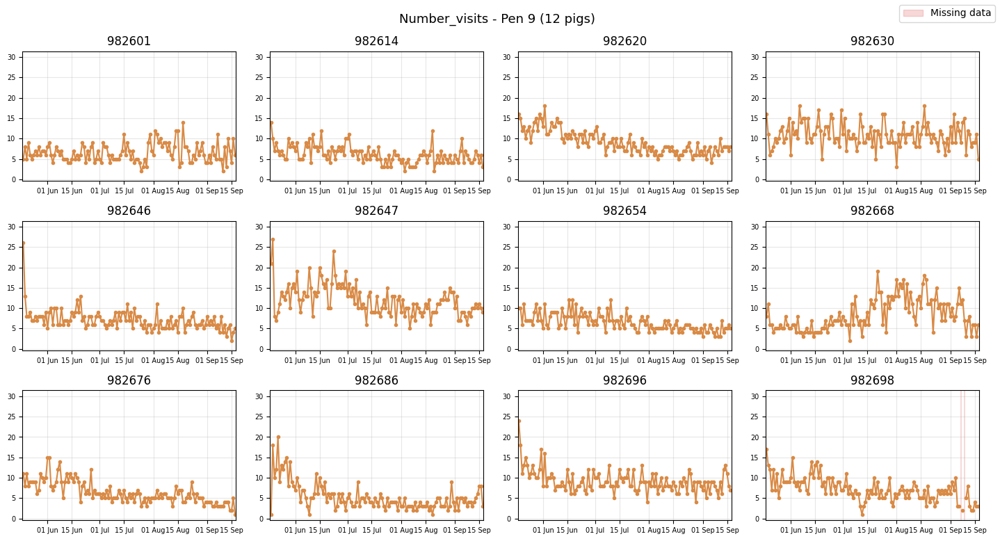

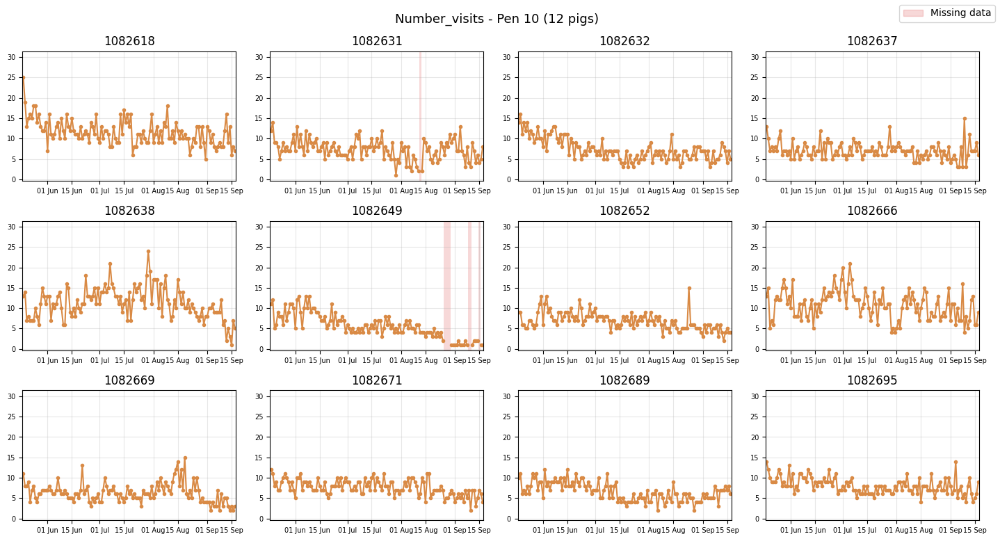

In [9]:
figs = plot_2D_grid(df, "Number_visits", color="#D98A45")   

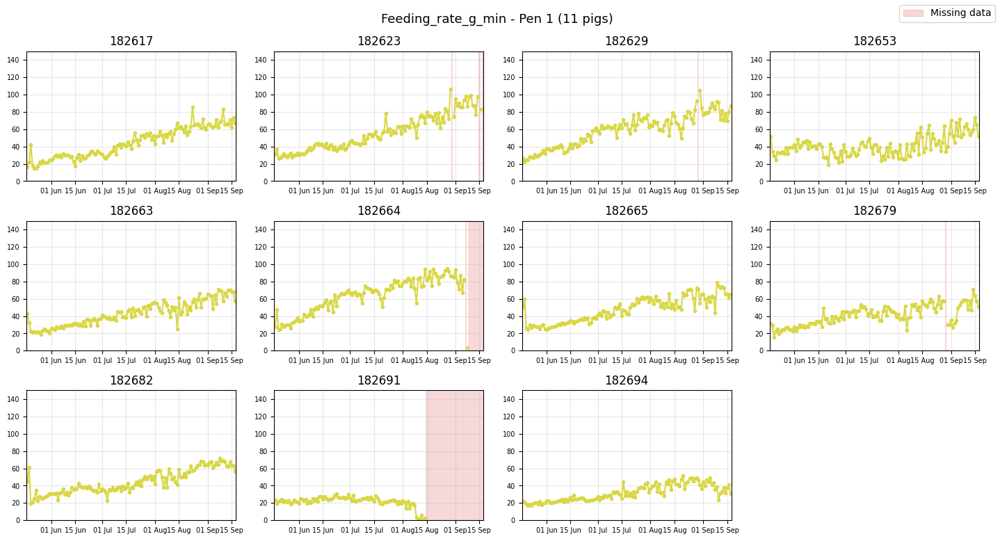

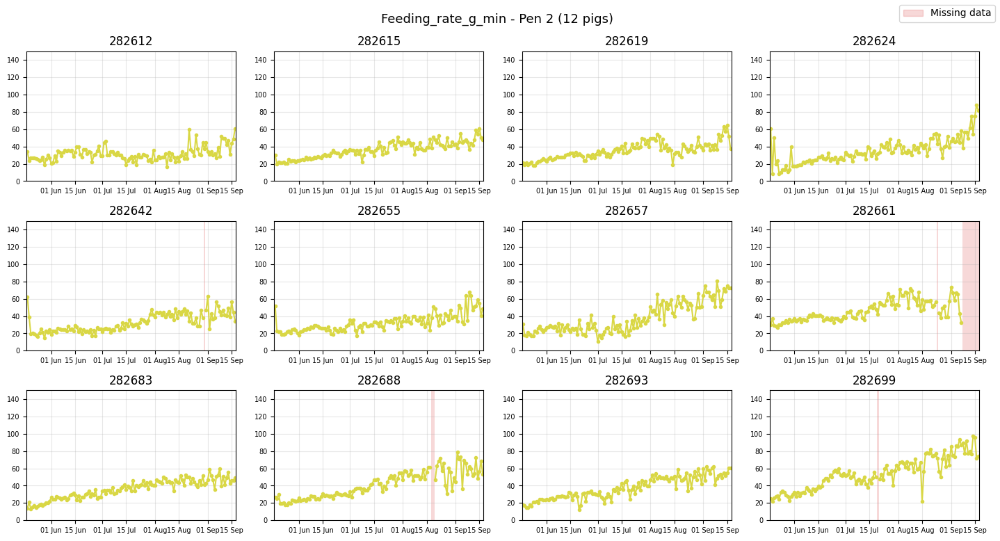

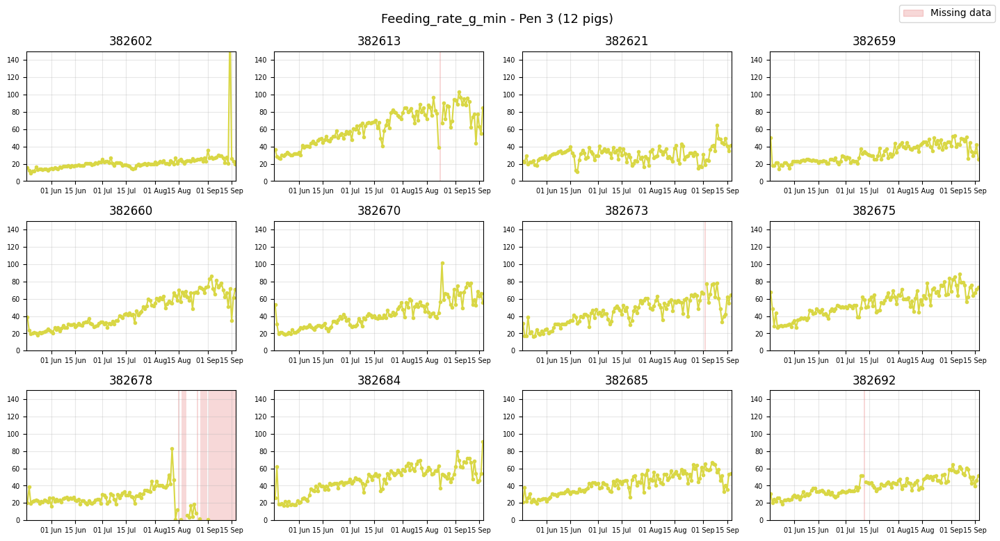

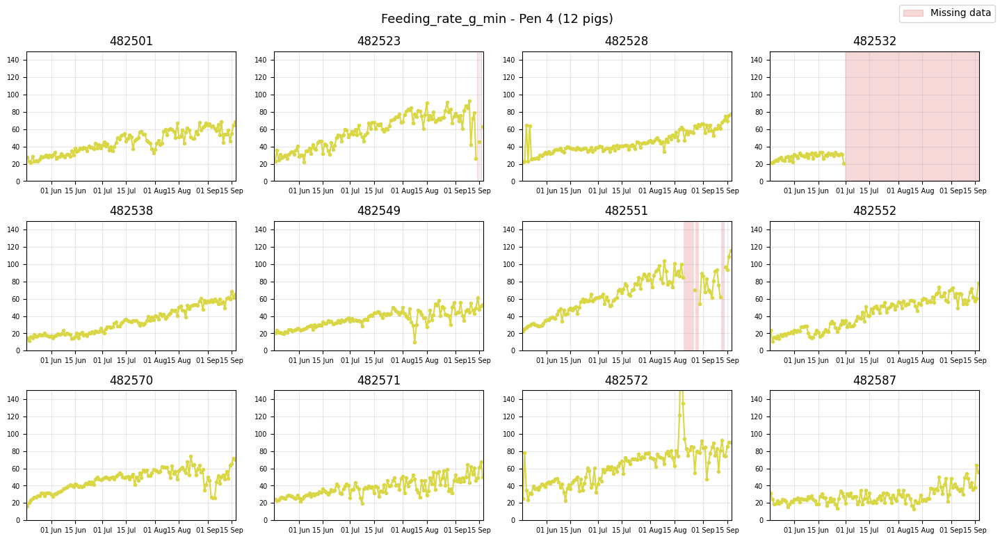

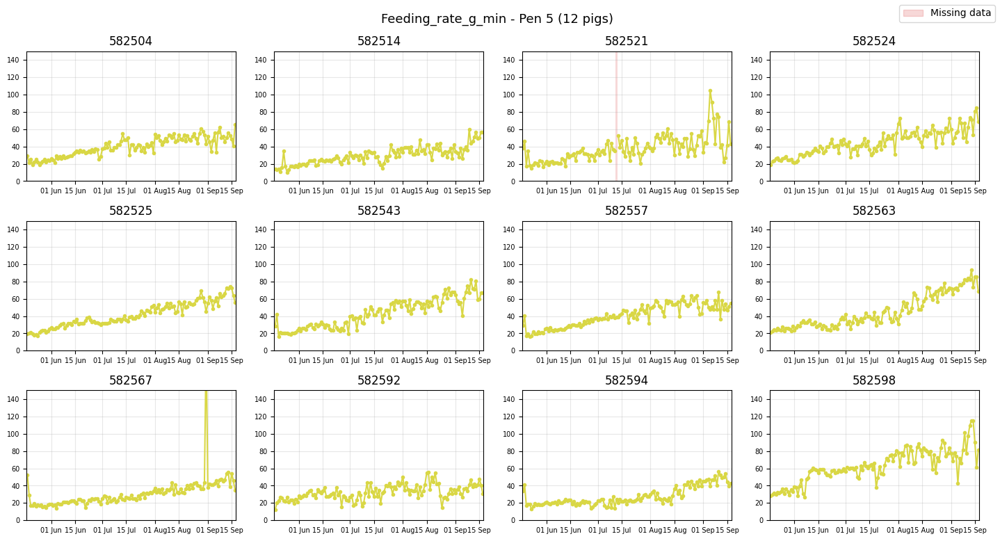

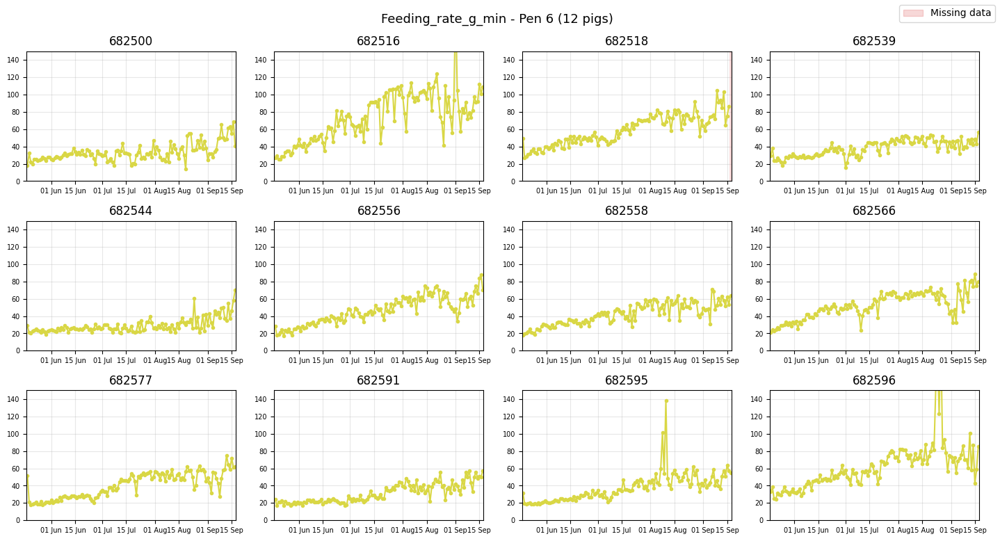

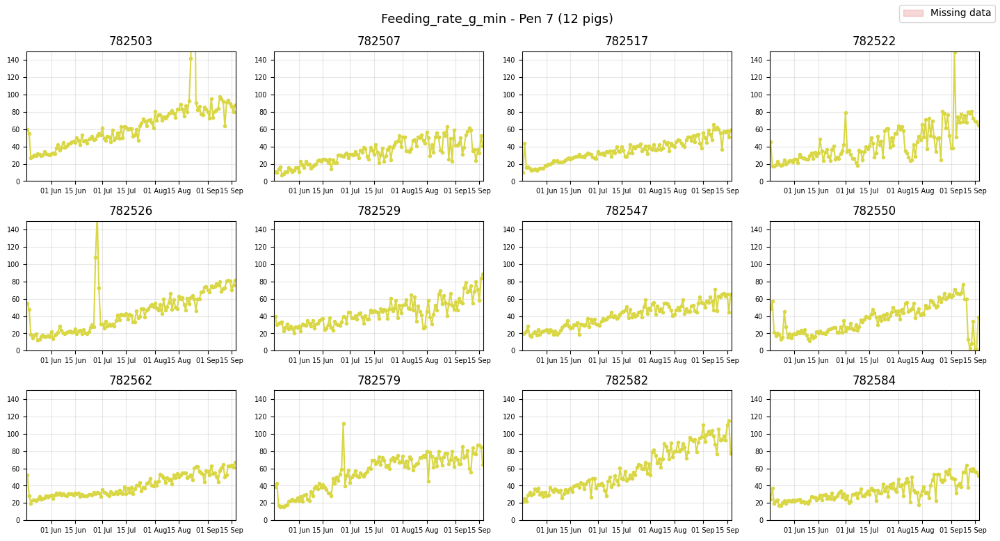

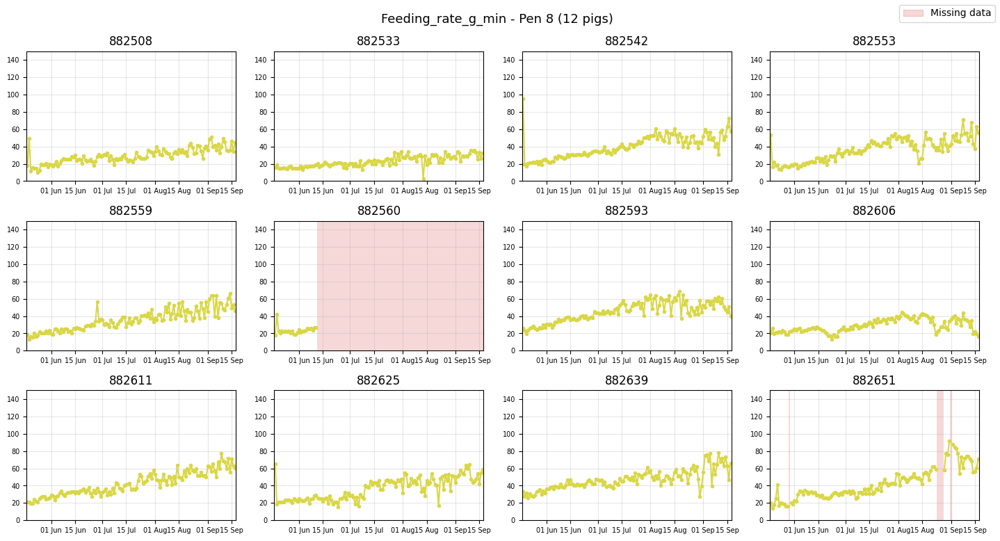

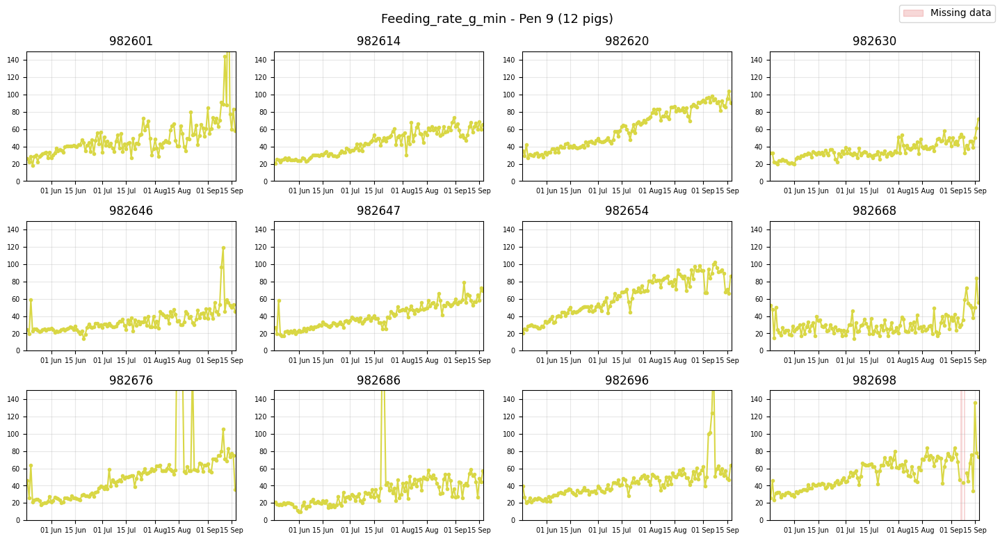

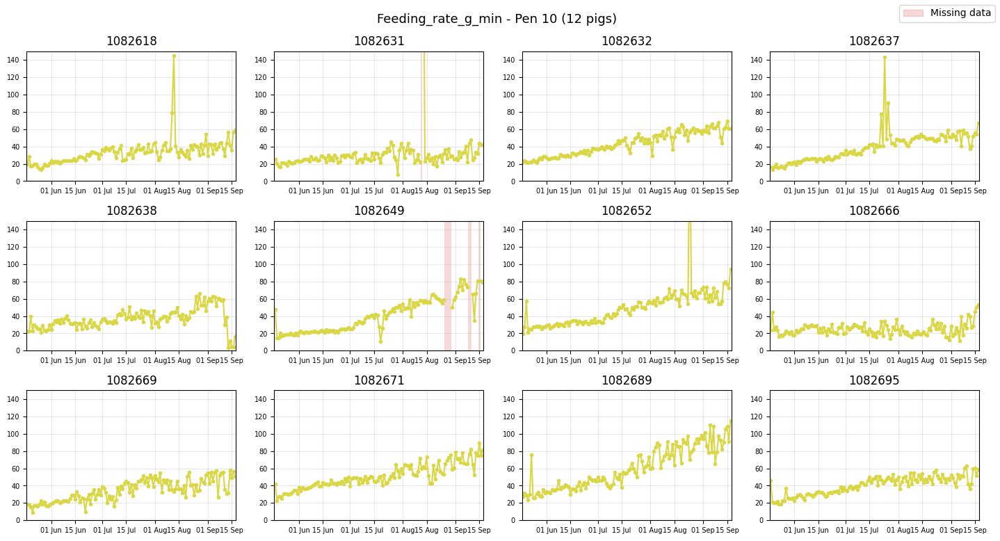

In [10]:
figs = plot_2D_grid(df, "Feeding_rate_g_min", color="#D9D745", ylim=(0,150))   

Feeding rate also appear to have an upward trend similar to intake. The rate falls in some intervals, which could also be an indicator of incidence.

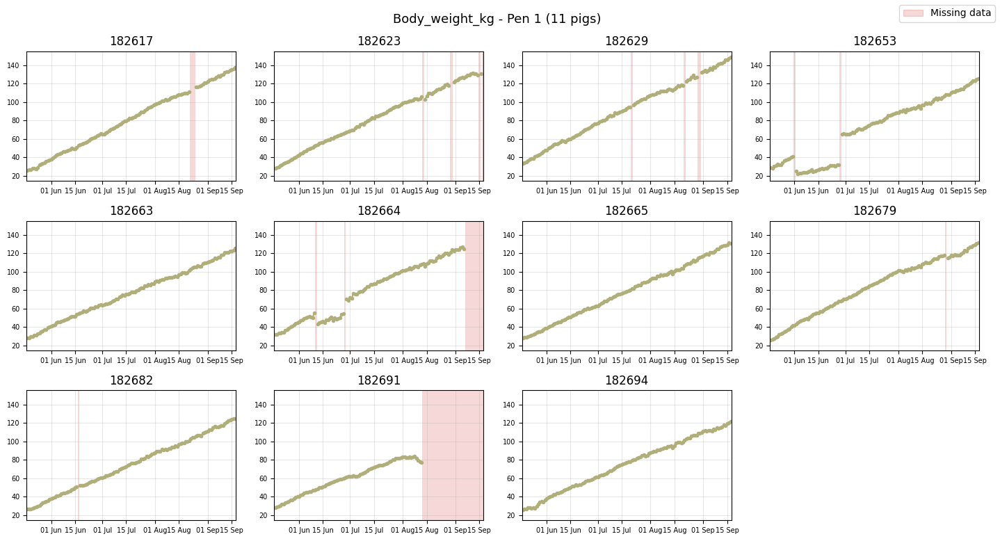

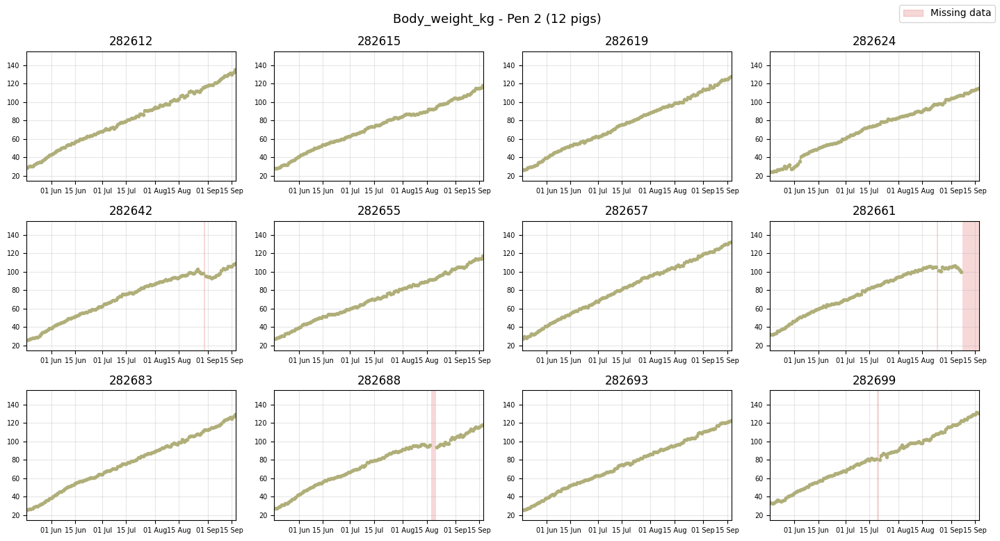

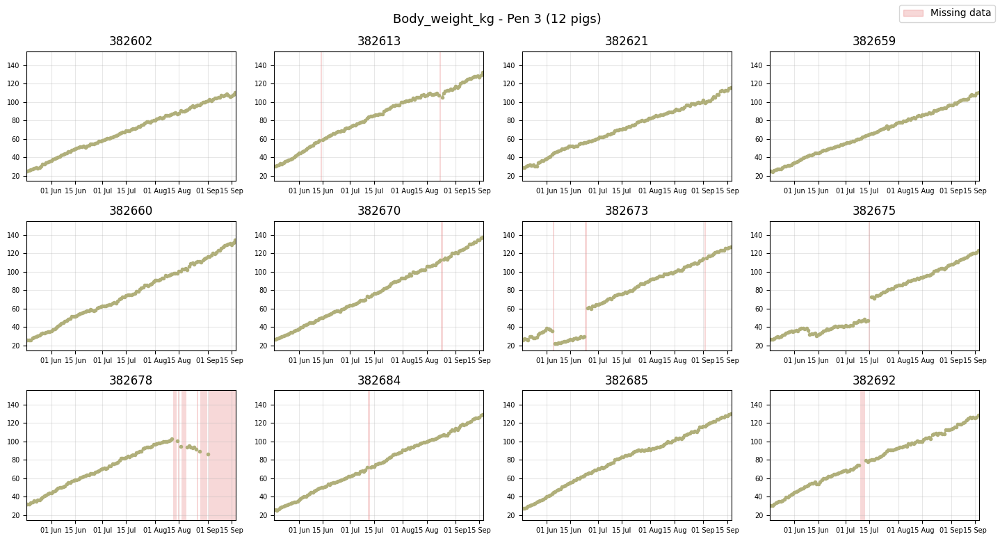

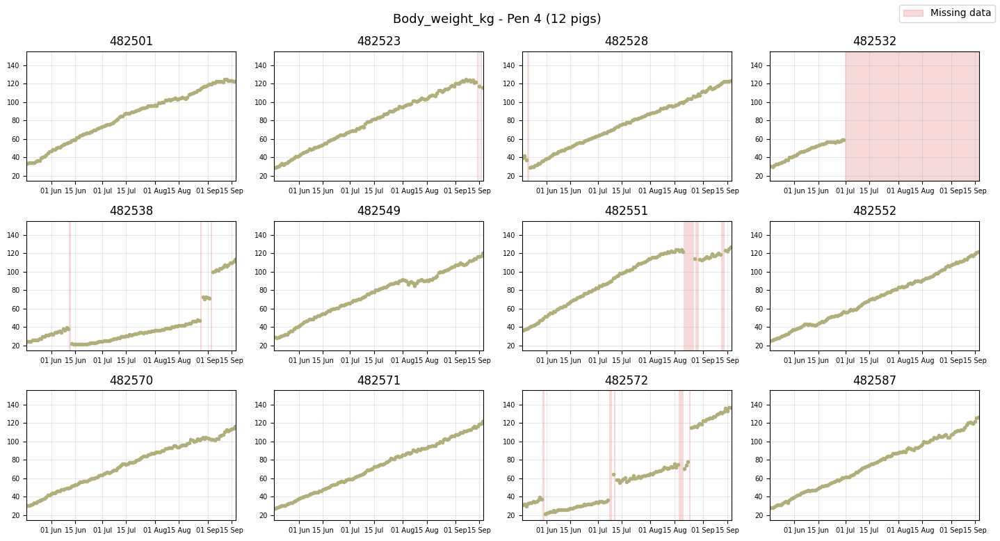

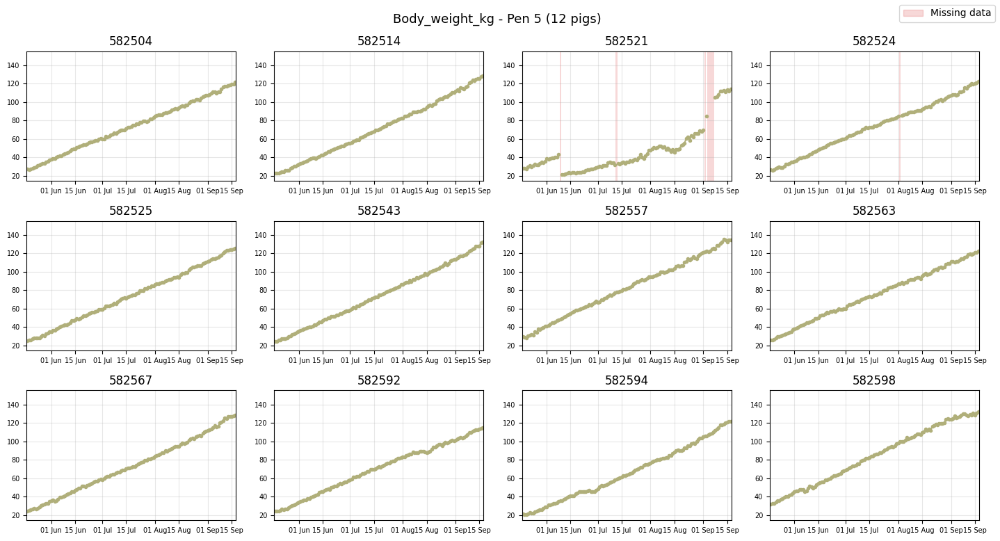

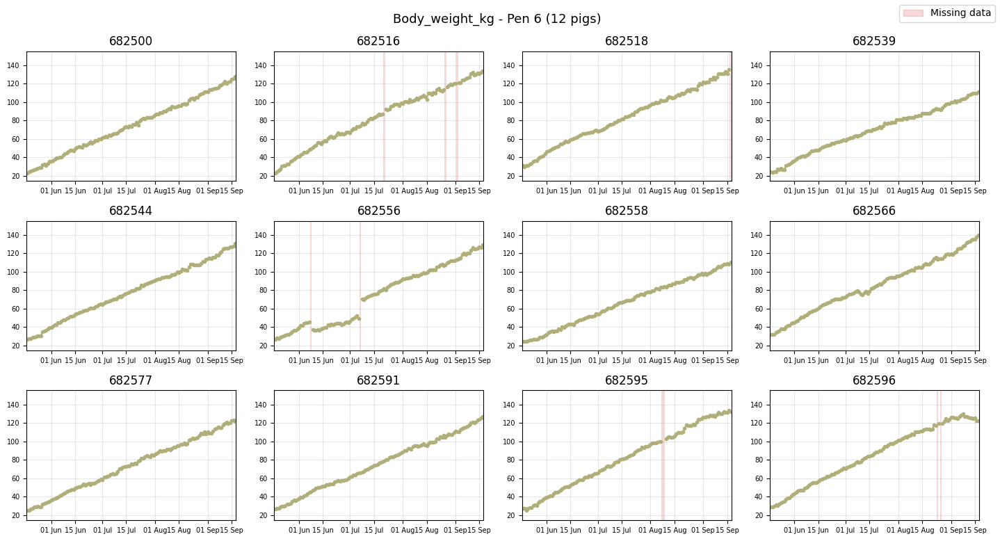

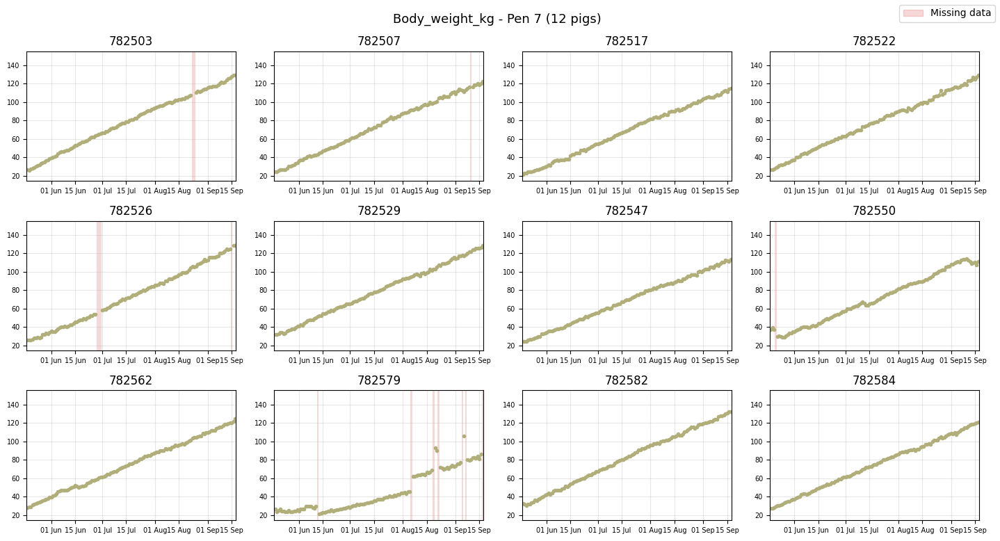

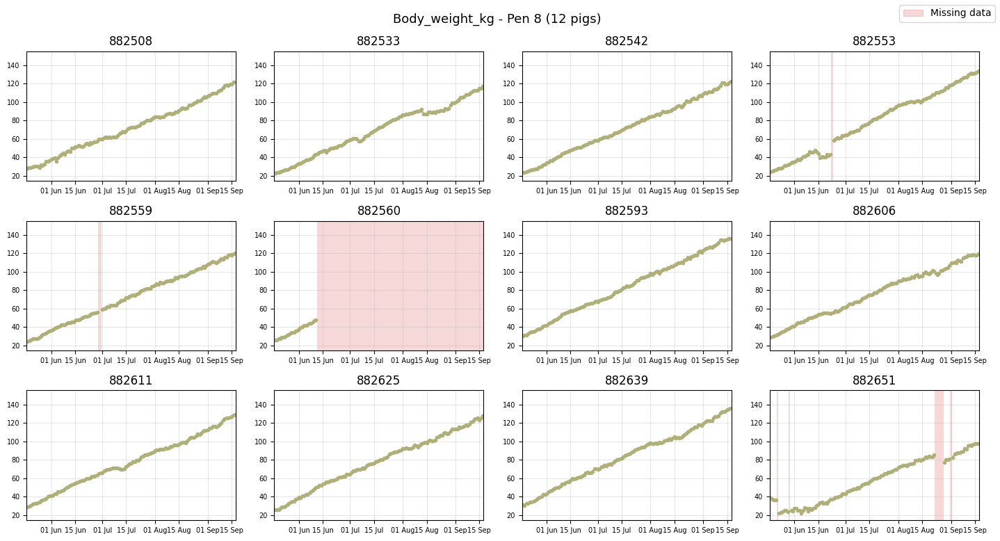

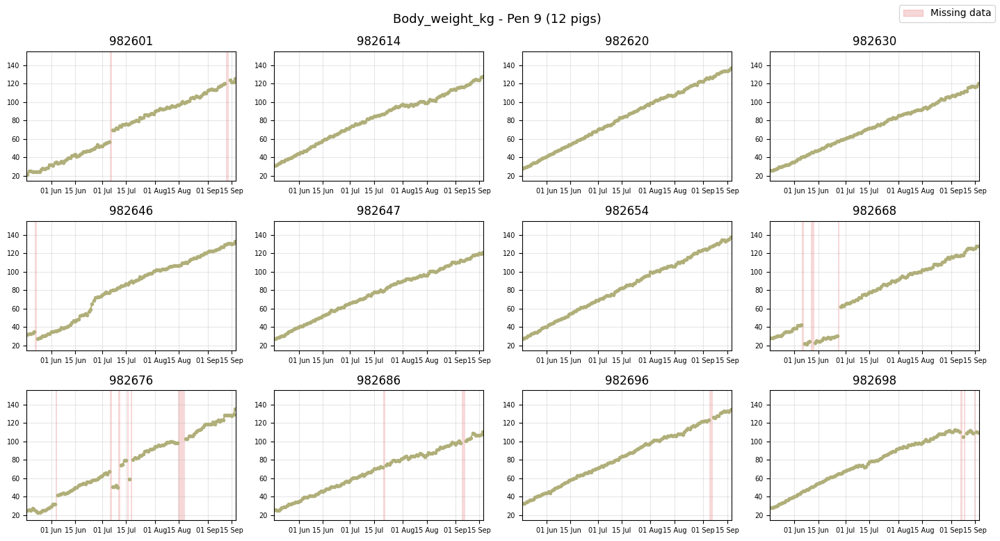

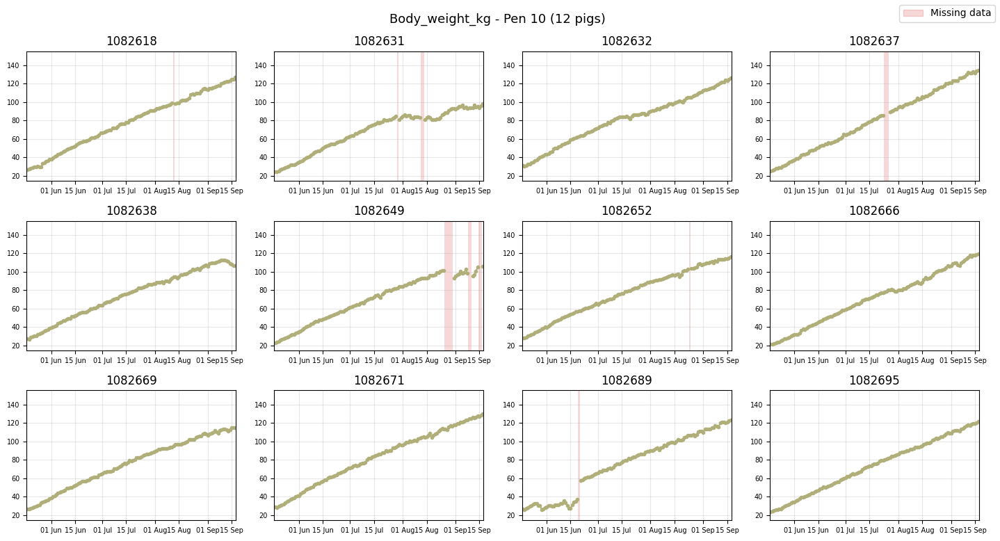

In [11]:
figs = plot_2D_grid(df, "Body_weight_kg", color="#B0AF7A")   

In most cases, body weight appears to have a linear increasing trend, but there are some anomalies. Some graphs appear to be discontous.

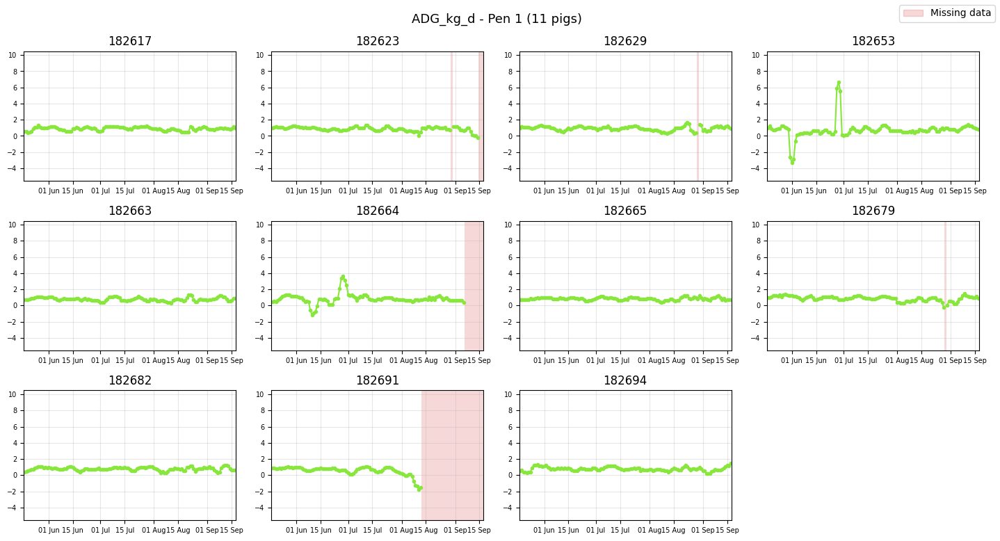

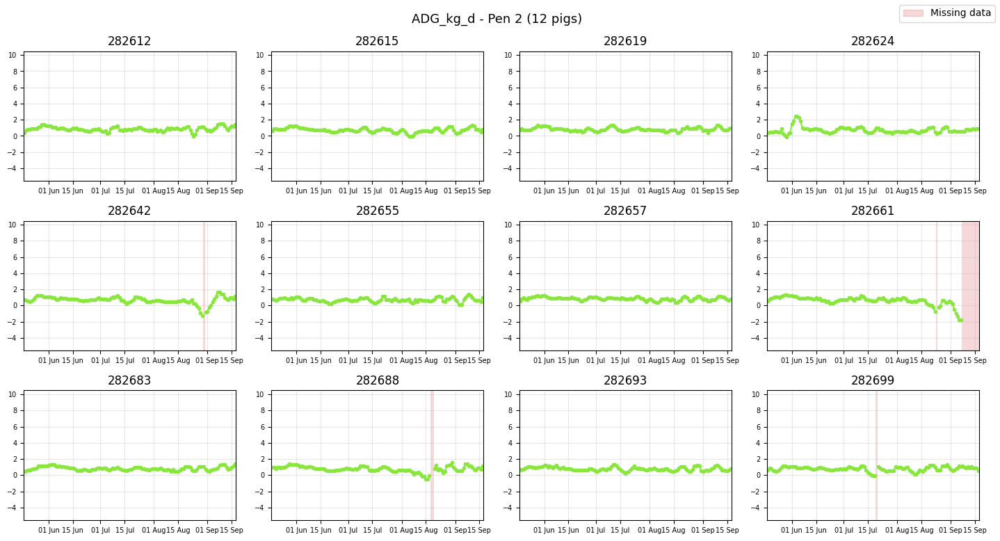

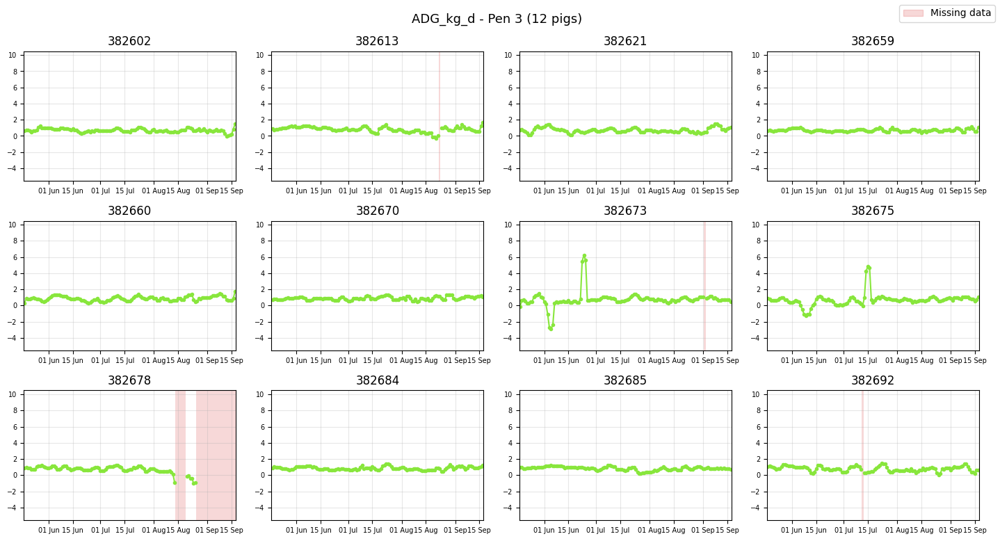

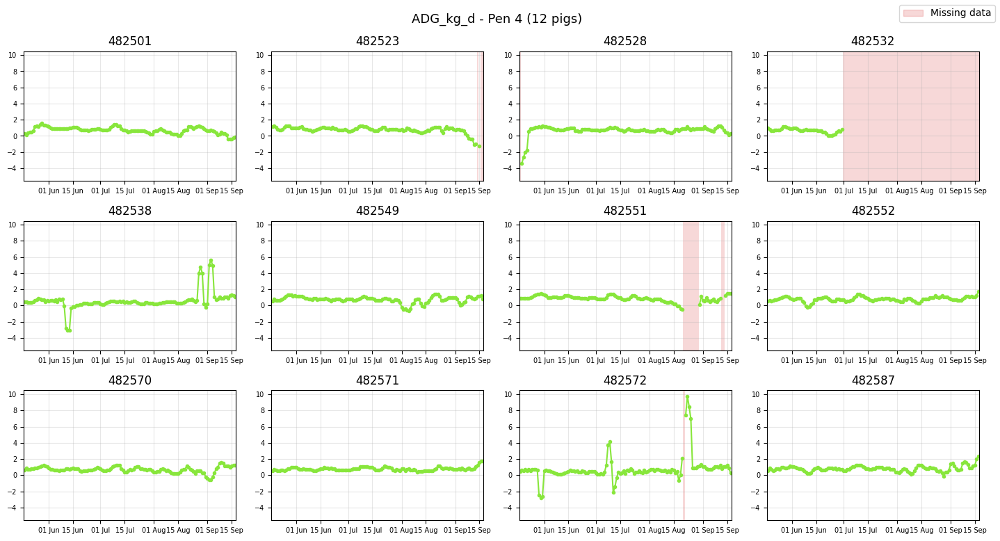

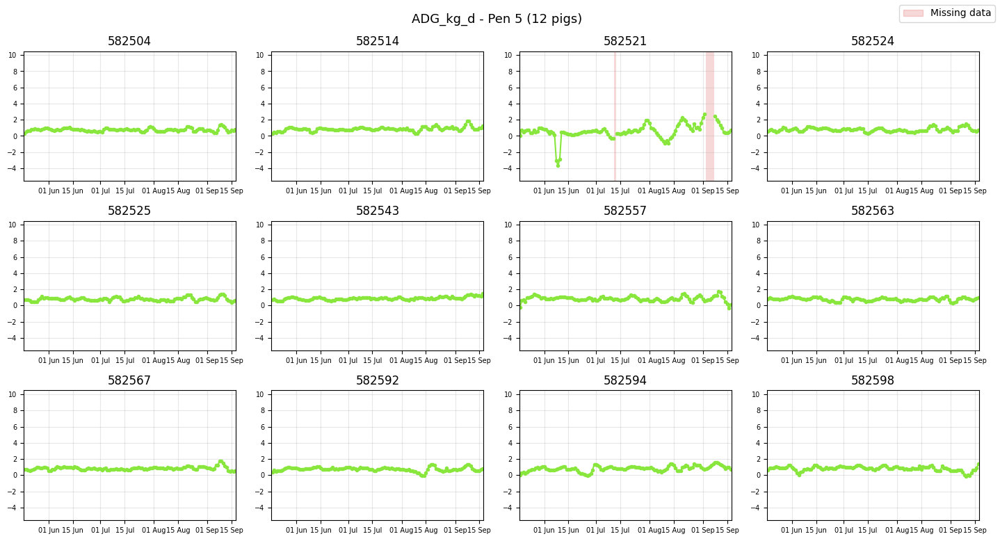

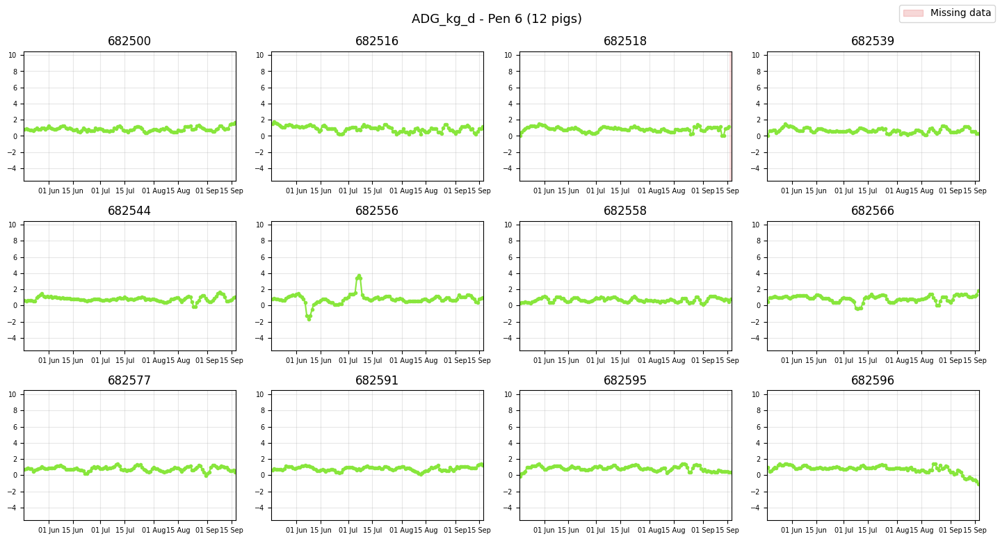

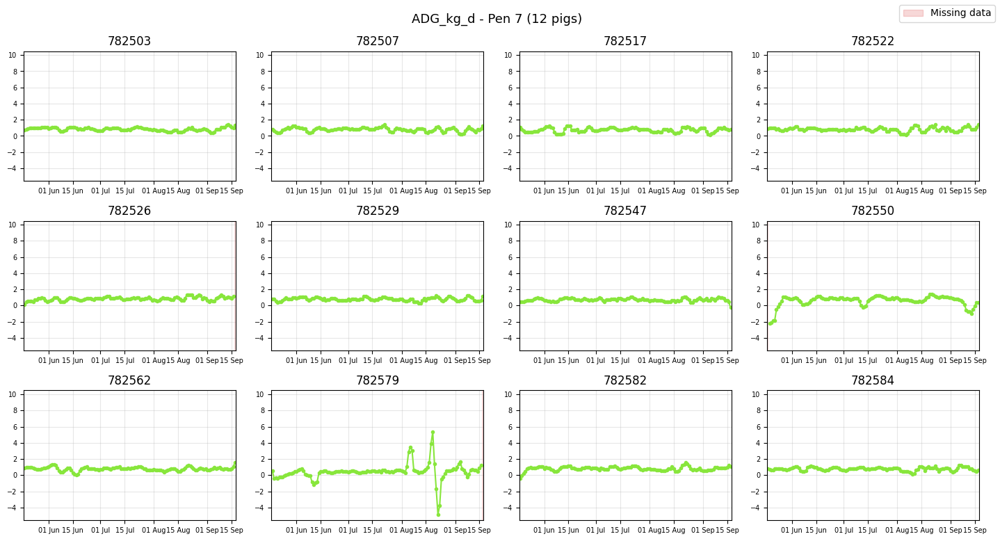

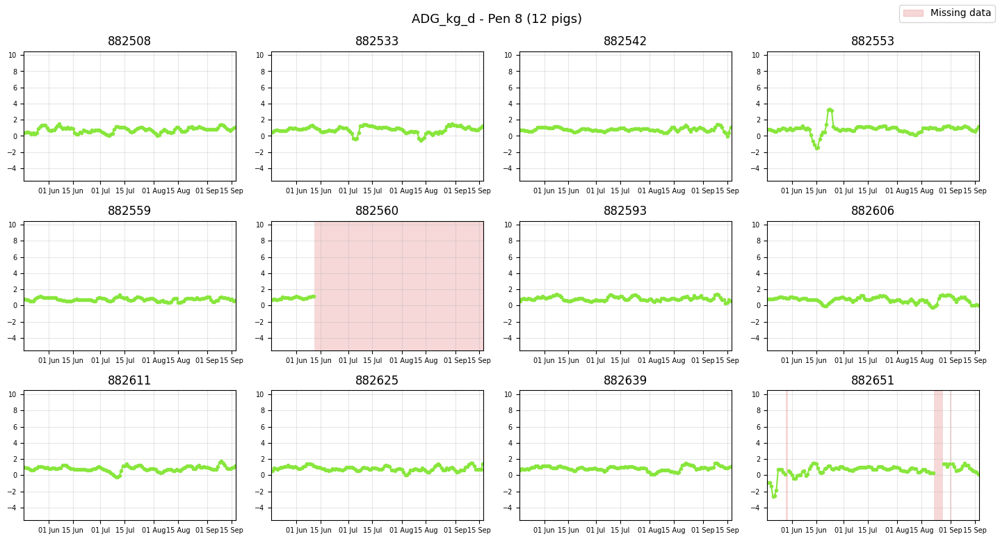

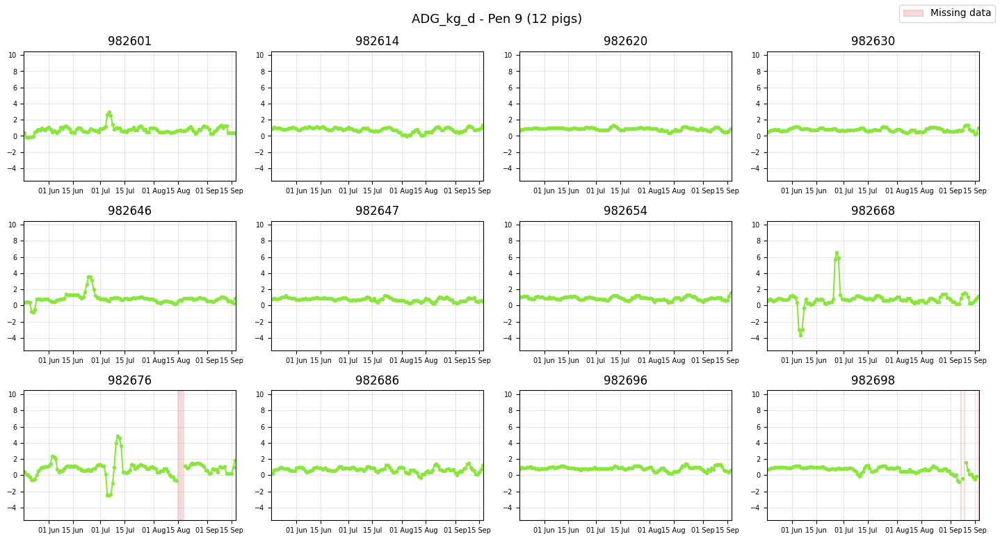

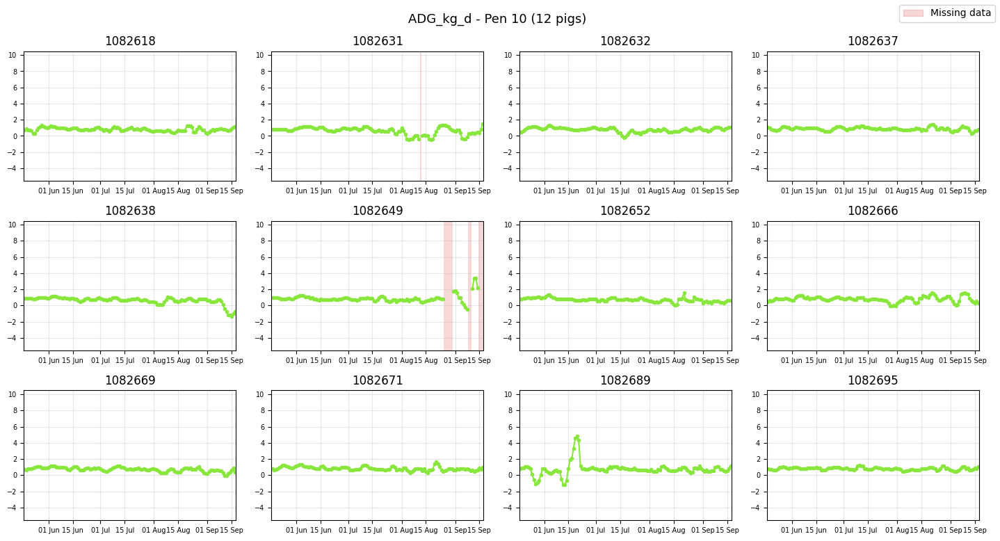

In [12]:
figs = plot_2D_grid(df, "ADG_kg_d", color="#88E63C",)   

`ADG` appears to be pretty much constant, with some outliers which could be due to mesurement inconsistencies.

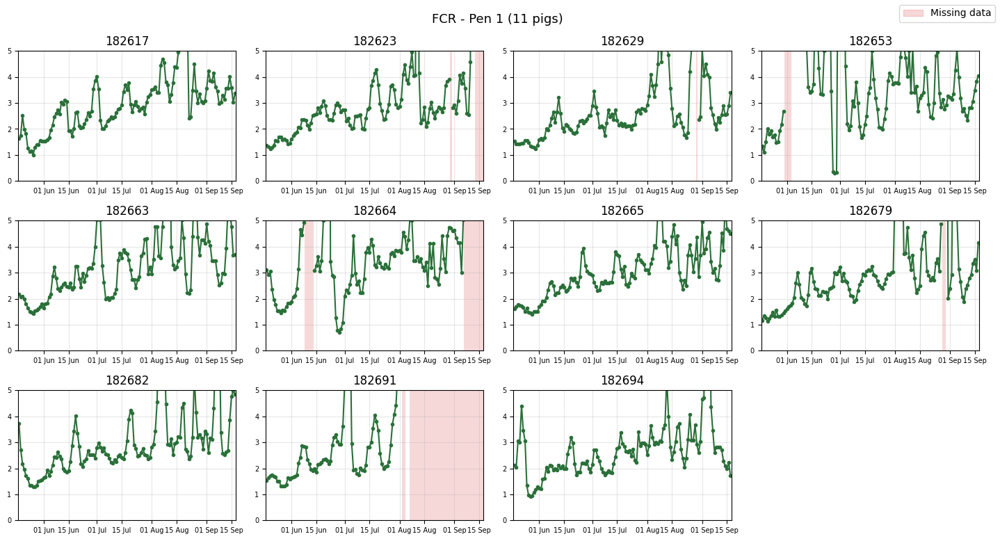

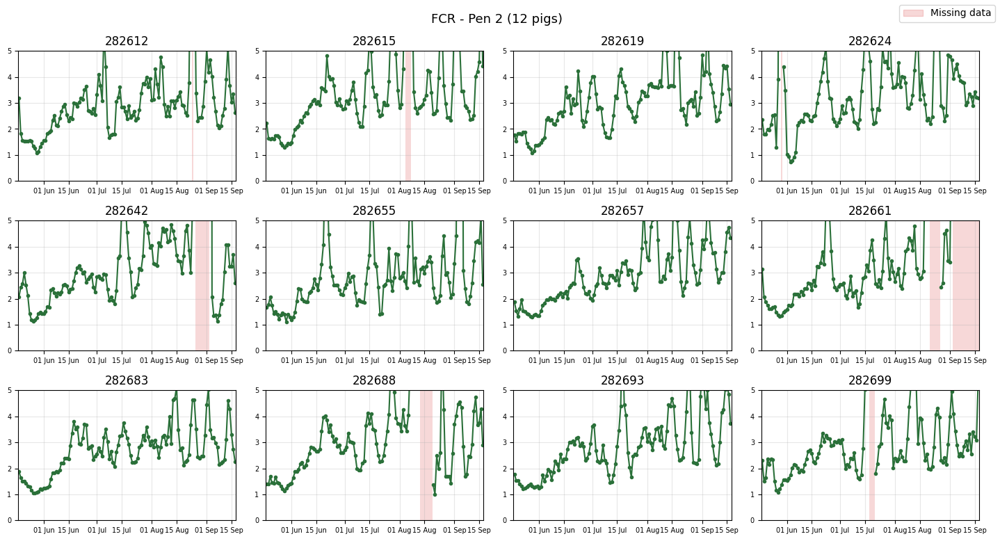

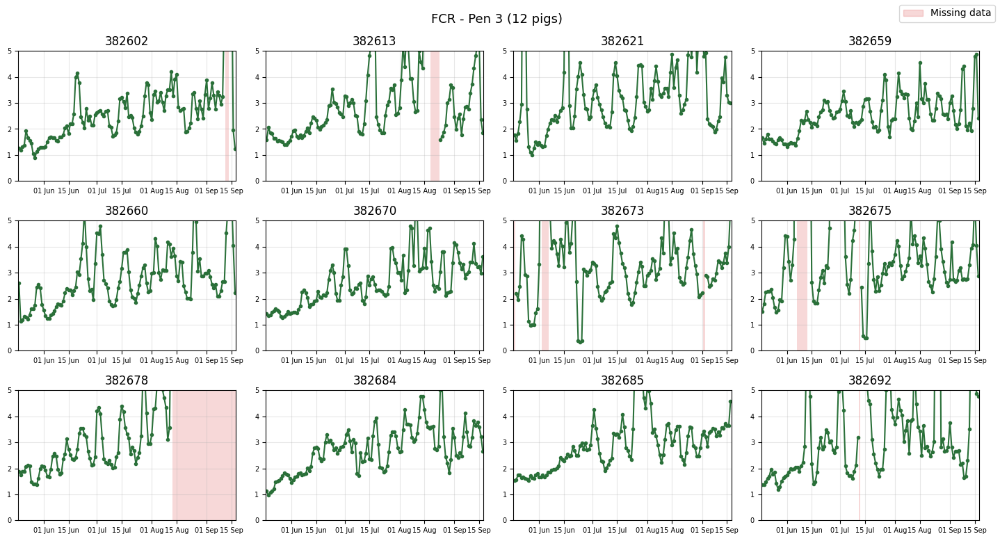

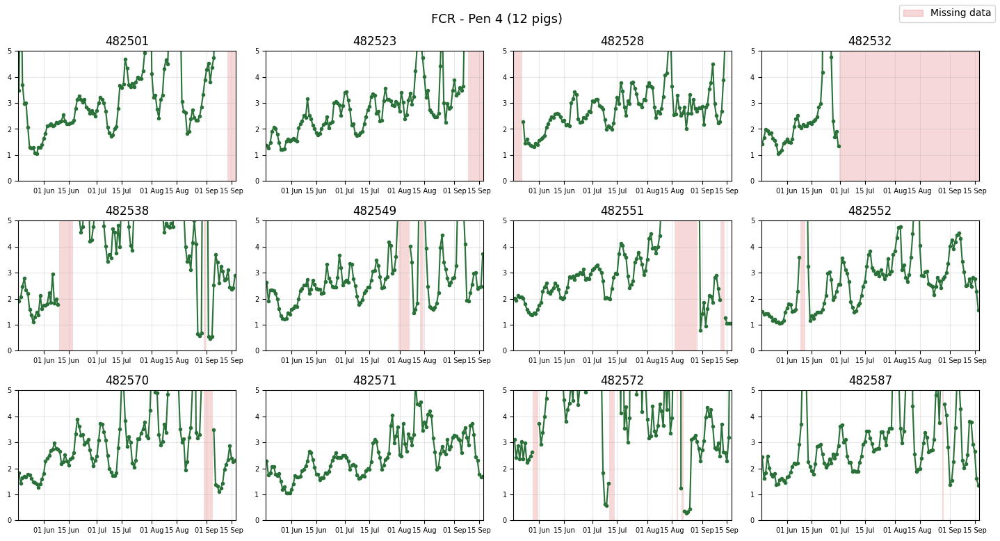

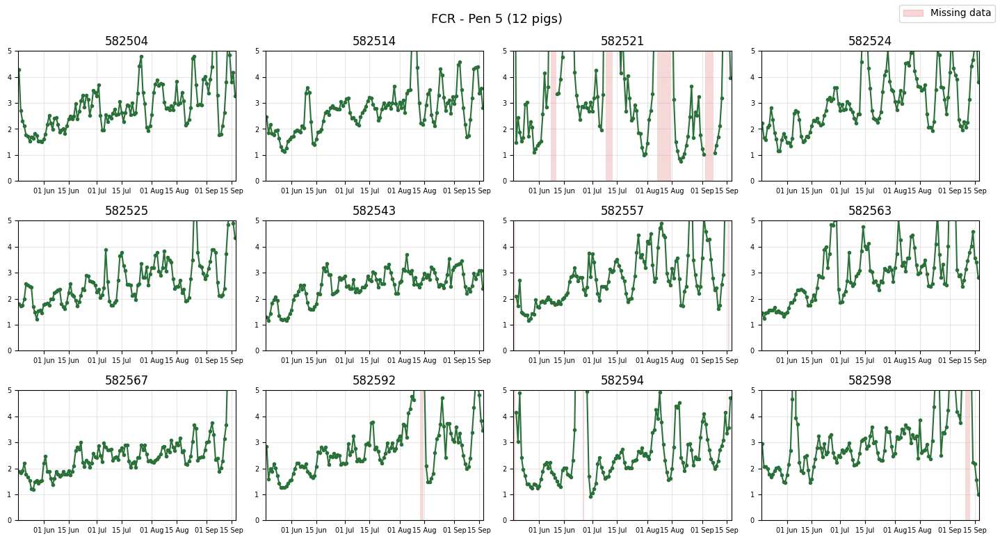

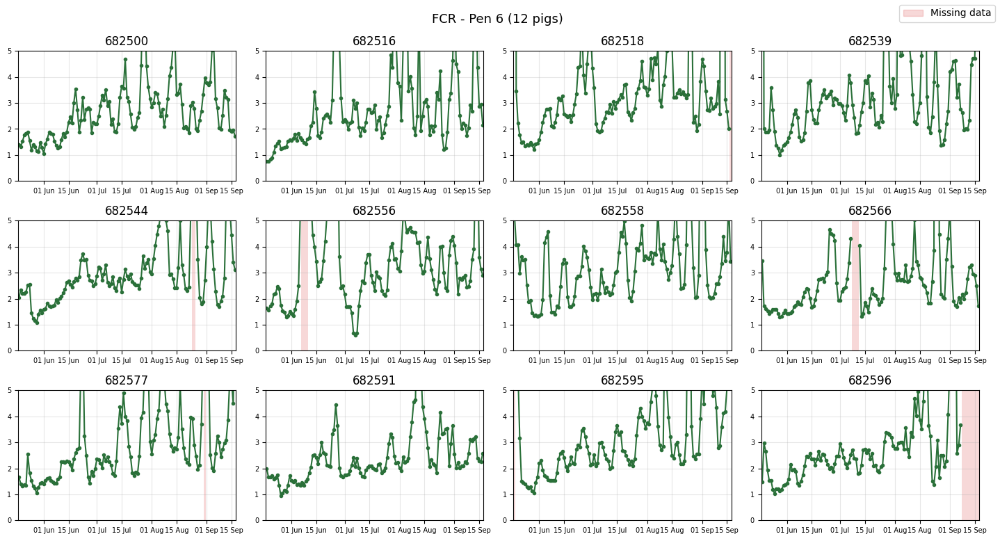

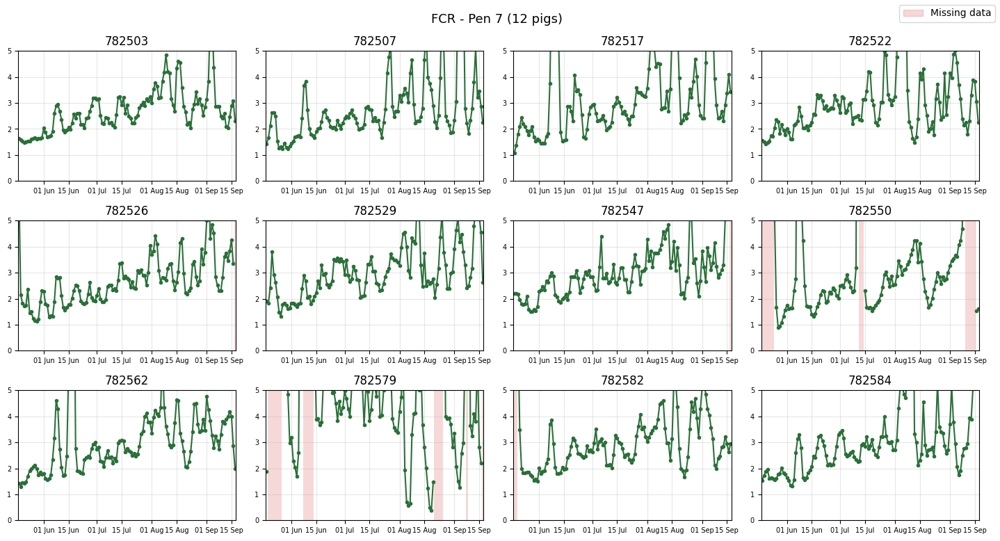

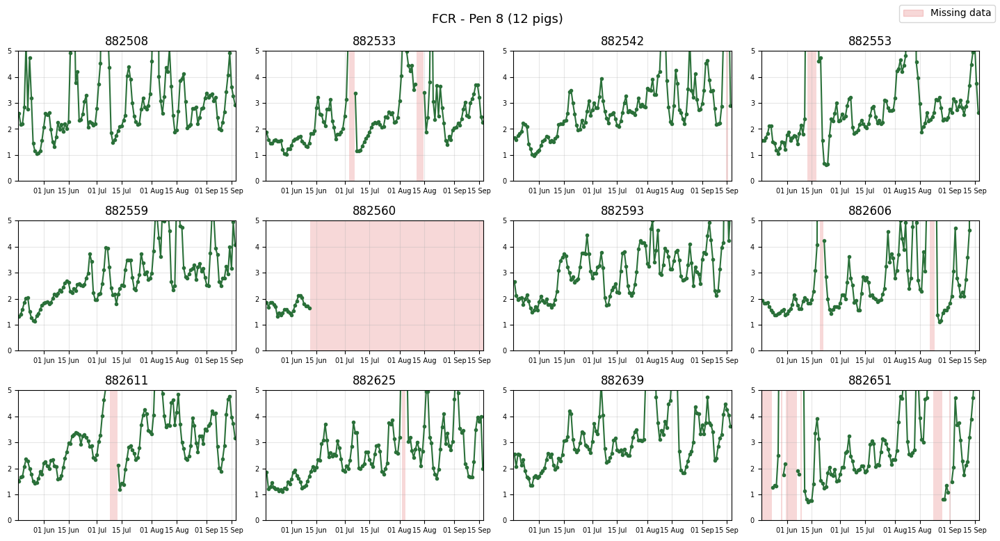

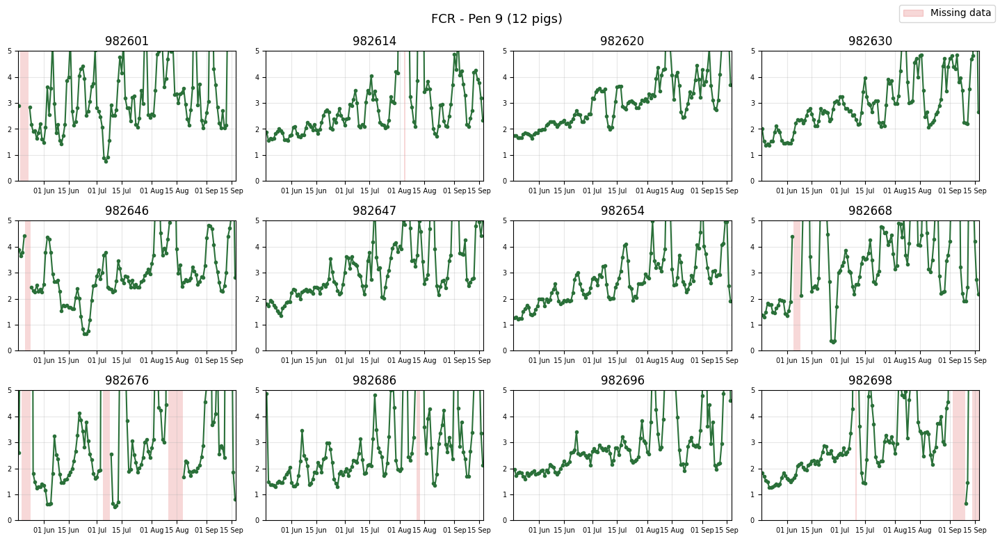

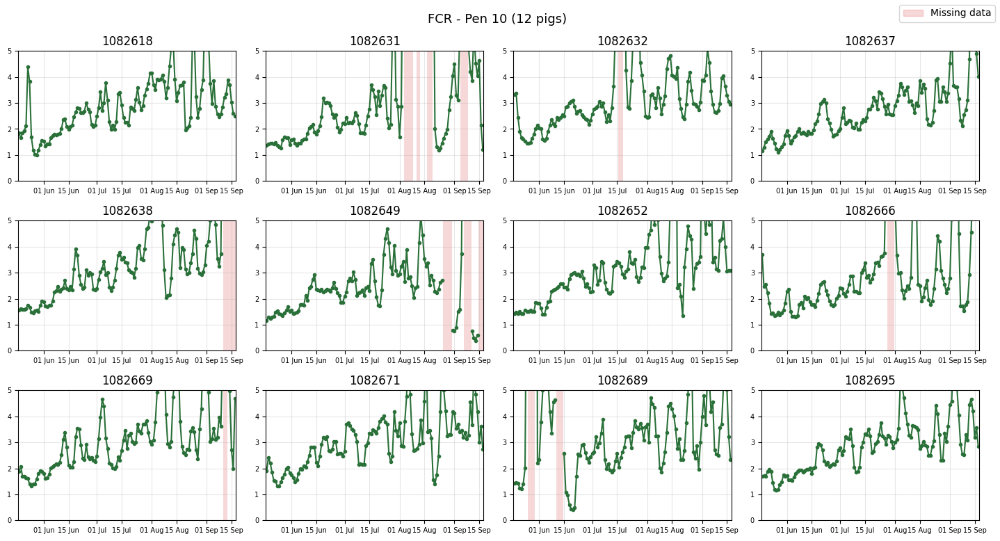

In [13]:
figs = plot_2D_grid(df, "FCR", color="#2A7039", ylim=(0, 5))   

`FCR` appears to have an upward trend with some extreme outliers

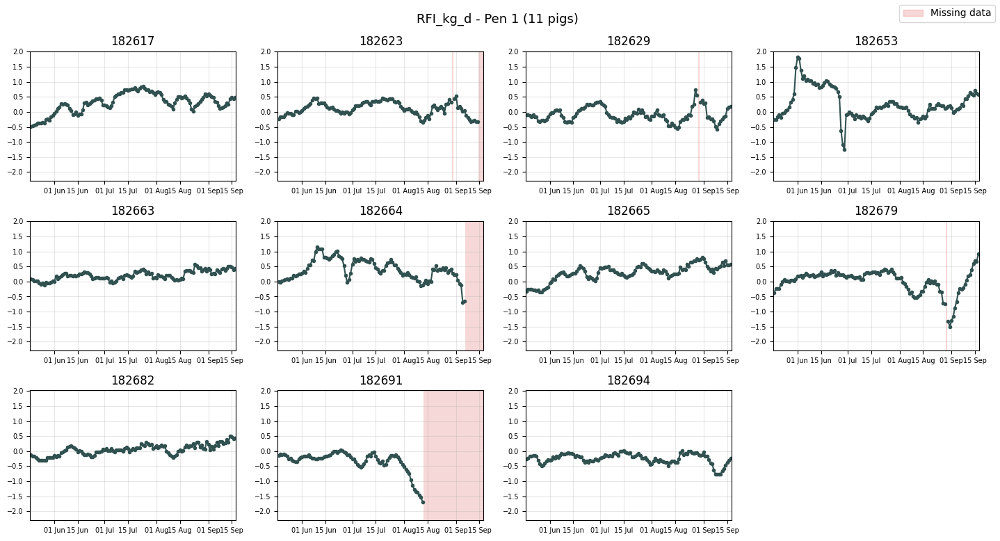

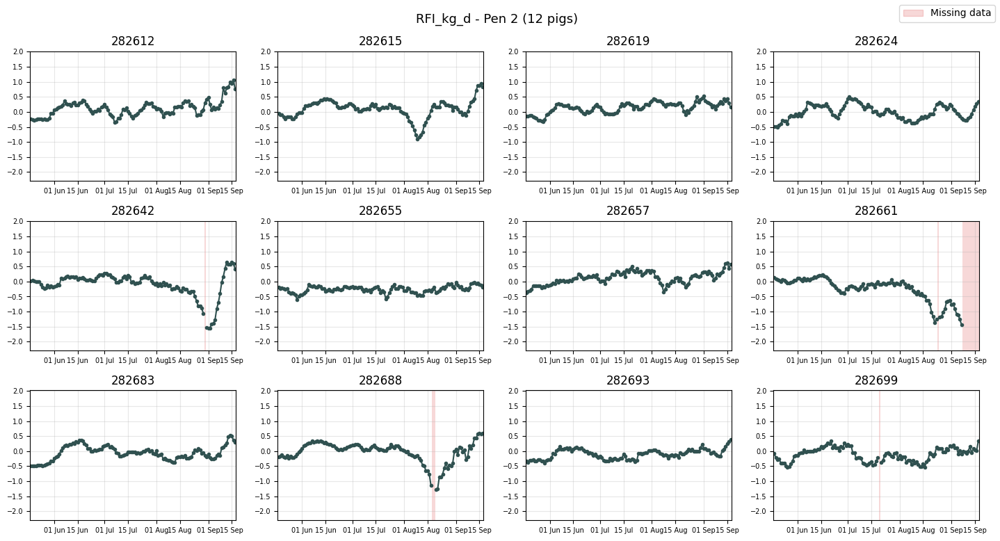

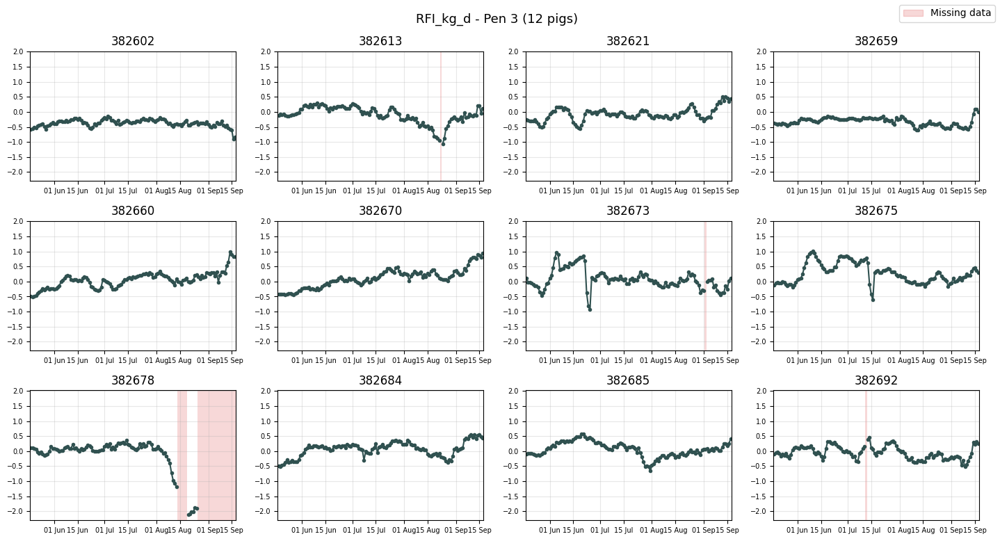

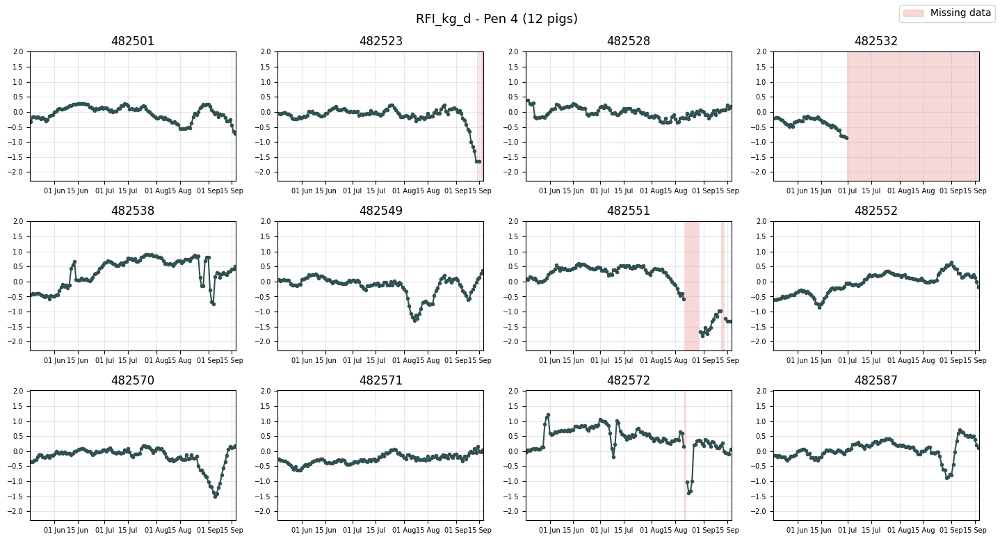

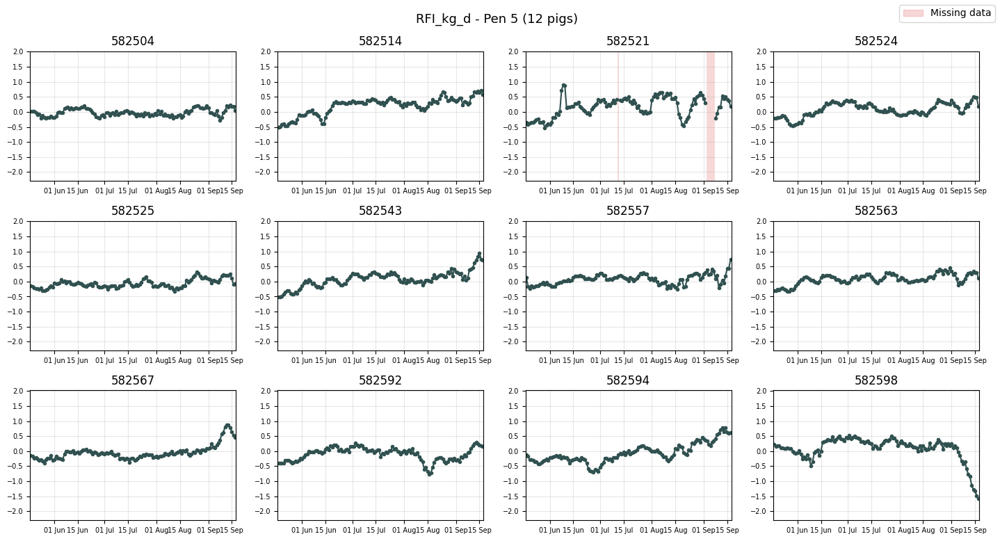

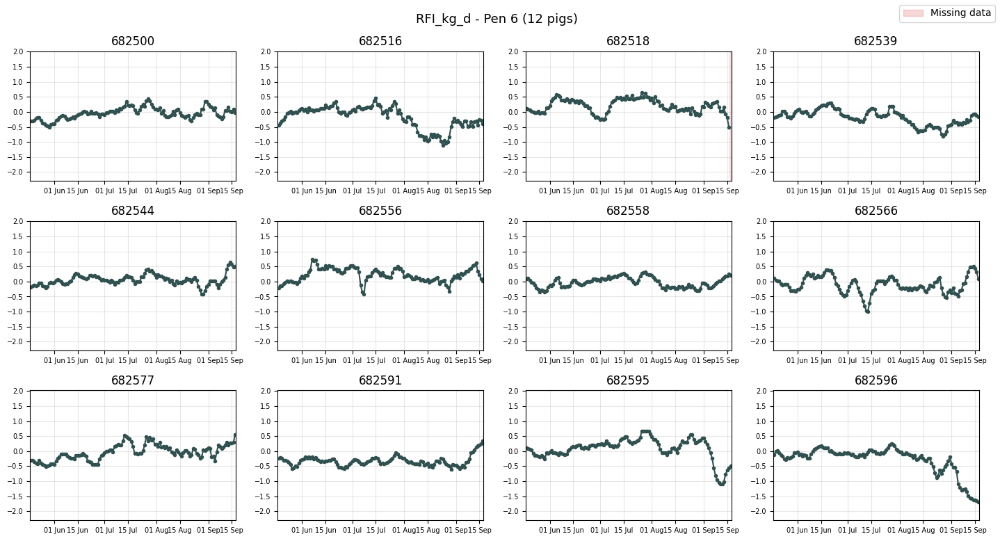

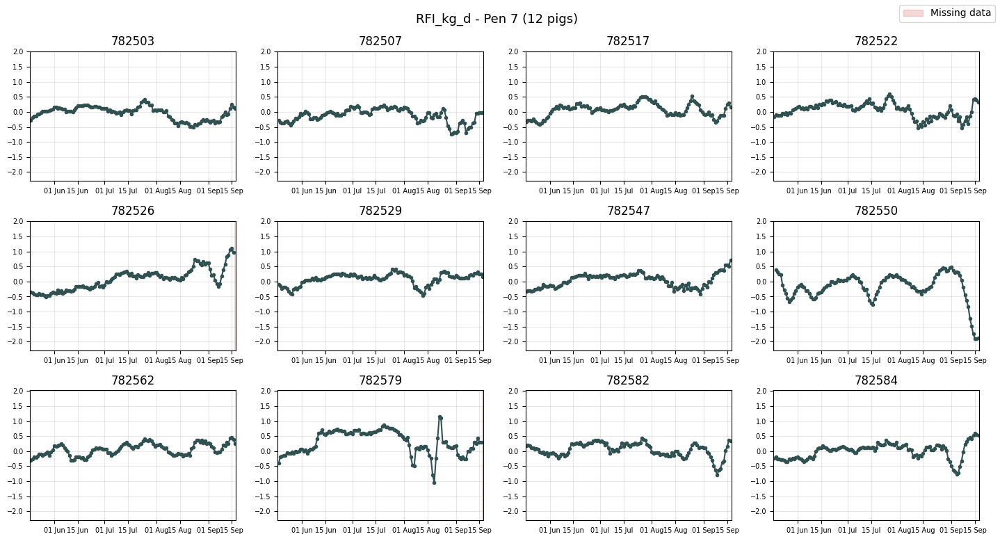

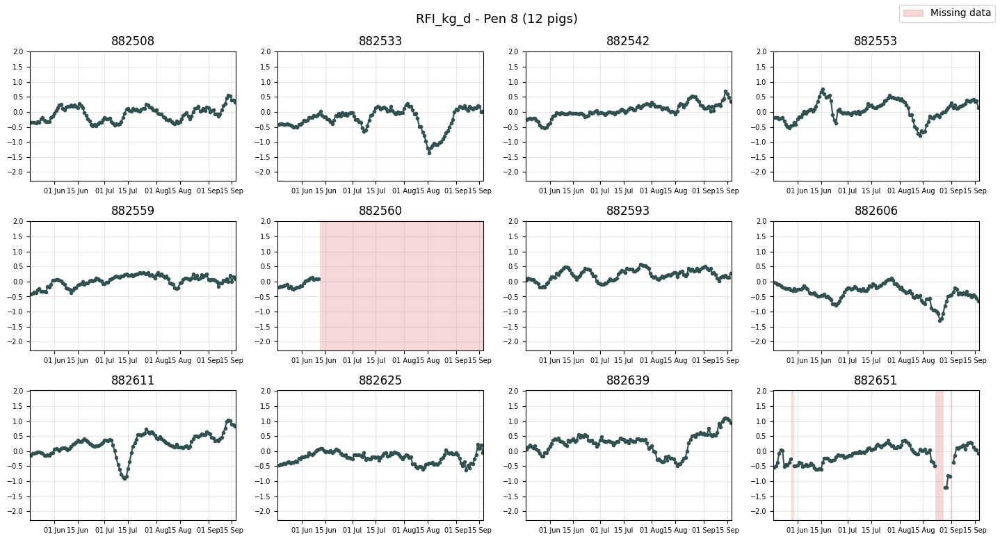

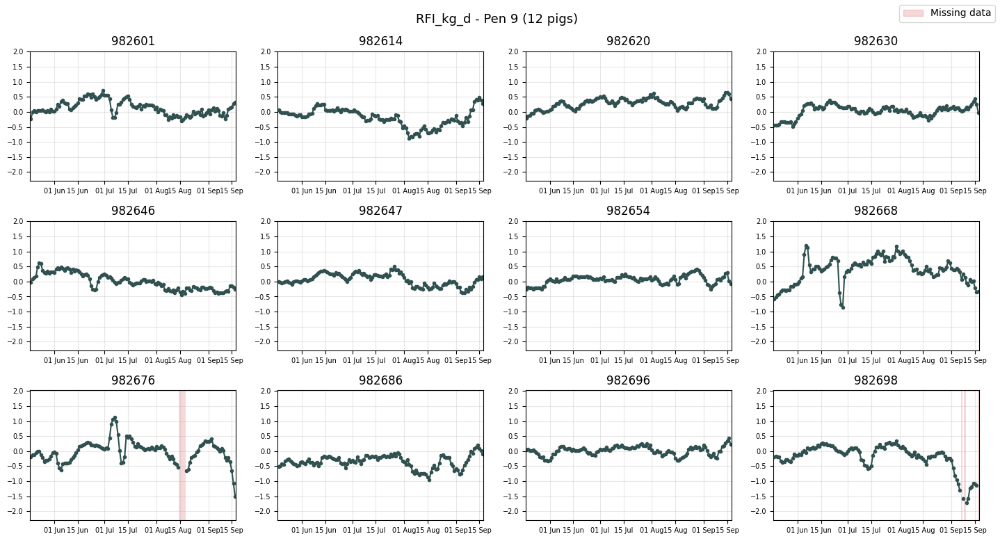

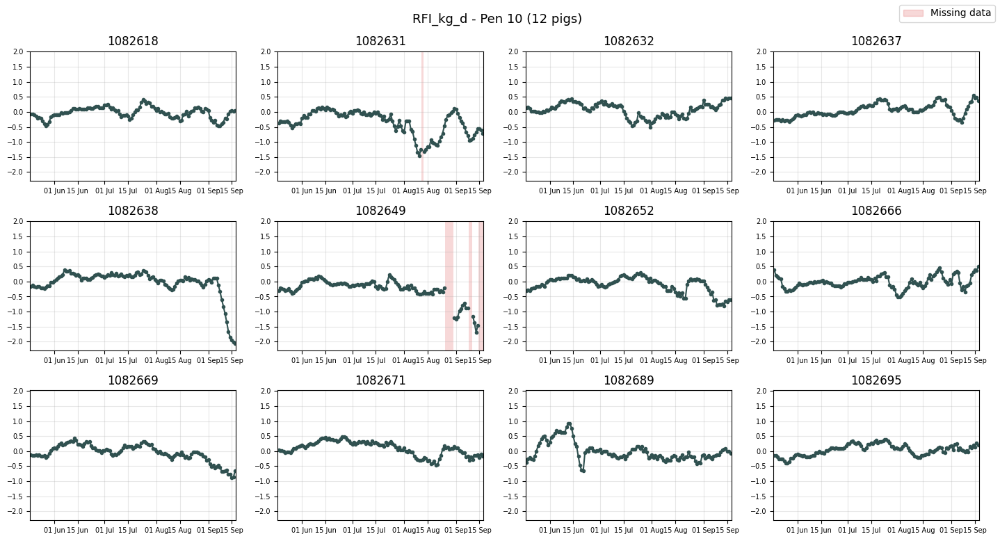

In [14]:
figs = plot_2D_grid(df, "RFI_kg_d", color="#305150")  

`RFI` appears to be sort of constant, with some variations in different cases.

## 2. Which is the mean and variance and how much of it is explained by pig-level differences and pen-level differences

In [15]:
from utils import summary_stats, variance_table, plot_variance_table, residual_autocorr

### Computing statistics: Mean, variance, skew... of different variables

In [16]:
summary_stats(df, ["Respiratory_score"])

,count,missing_%,mean,std,var,min,25%,50%,75%,max,skew,kurt
Respiratory_score,14361.0,0.0,63.12,14.91,222.45,31.0,53.0,62.0,76.0,91.0,-0.09,-0.89


In [17]:
summary_stats(df, ["Water_use_L"])

,count,missing_%,mean,std,var,min,25%,50%,75%,max,skew,kurt
Water_use_L,13197.0,8.11,11.76,6.02,36.26,2.25,7.25,11.09,14.45,43.67,1.2,2.36


In [18]:
cols = ["Feed_intake_kg", "Number_visits", "Duration_min", "Feeding_rate_g_min",
        "Body_weight_kg", "ADG_kg_d", "FCR", "RFI_kg_d"]

summary_stats(df, cols)

,count,missing_%,mean,std,var,min,25%,50%,75%,max,skew,kurt
Feed_intake_kg,14338.0,0.16,2.14,0.62,0.39,0.00,1.74,2.14,2.53,5.70,0.08,0.50
Number_visits,14338.0,0.16,8.38,3.69,13.58,1.00,6.00,8.00,10.00,30.00,0.94,1.39
Duration_min,14338.0,0.16,52.01,16.01,256.42,0.07,41.22,50.93,61.88,151.85,0.41,0.93
Feeding_rate_g_min,14338.0,0.16,42.00,19.15,366.59,0.28,28.03,38.55,52.28,330.00,2.06,14.79
Body_weight_kg,14230.0,0.91,75.22,29.34,860.94,20.67,50.27,75.95,99.00,148.86,0.01,-1.09
ADG_kg_d,14309.0,0.36,0.79,0.44,0.20,-4.86,0.62,0.80,0.97,9.75,1.68,57.18
FCR,13987.0,2.60,3.33,6.95,48.31,0.28,2.10,2.70,3.47,492.40,40.75,2285.67
RFI_kg_d,14309.0,0.36,0.00,0.33,0.11,-2.10,-0.19,0.02,0.20,1.82,-0.61,3.38


### Variance descomposition

How do different factors (individual pig differences, time, pen differences...) affect to variance by proportion?

Interpretation:

- Week (purple): Differences between weeks

- Day (Blue): Differences between days in the same week
- Pen (Green): Differences between pens
- Pig (Light green): Differences between pigs
- Residual: Not explained by the factors above

c:\Users\ericp\Desktop\PigLF\PigLF-health-forecast\EDA\../src\utils.py:612: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return res.fillna("-")


<Axes: xlabel='% of total variance'>

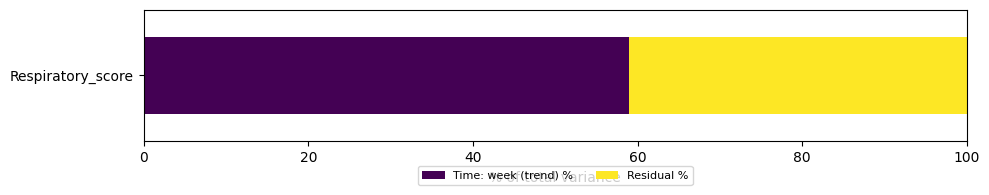

In [19]:
r = variance_table(df, ["Respiratory_score"])
plot_variance_table(r)

c:\Users\ericp\Desktop\PigLF\PigLF-health-forecast\EDA\../src\utils.py:612: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return res.fillna("-")


<Axes: xlabel='% of total variance'>

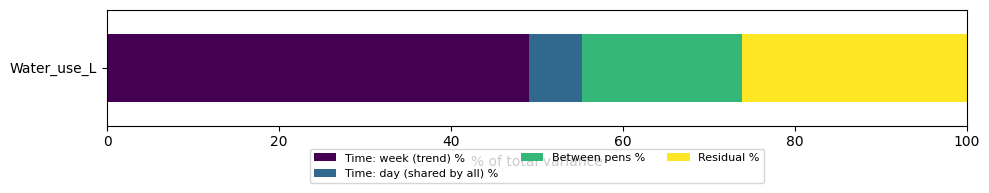

In [20]:
w = variance_table(df, ["Water_use_L"])
plot_variance_table(w)


c:\Users\ericp\Desktop\PigLF\PigLF-health-forecast\EDA\../src\utils.py:612: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return res.fillna("-")


<Axes: xlabel='% of total variance'>

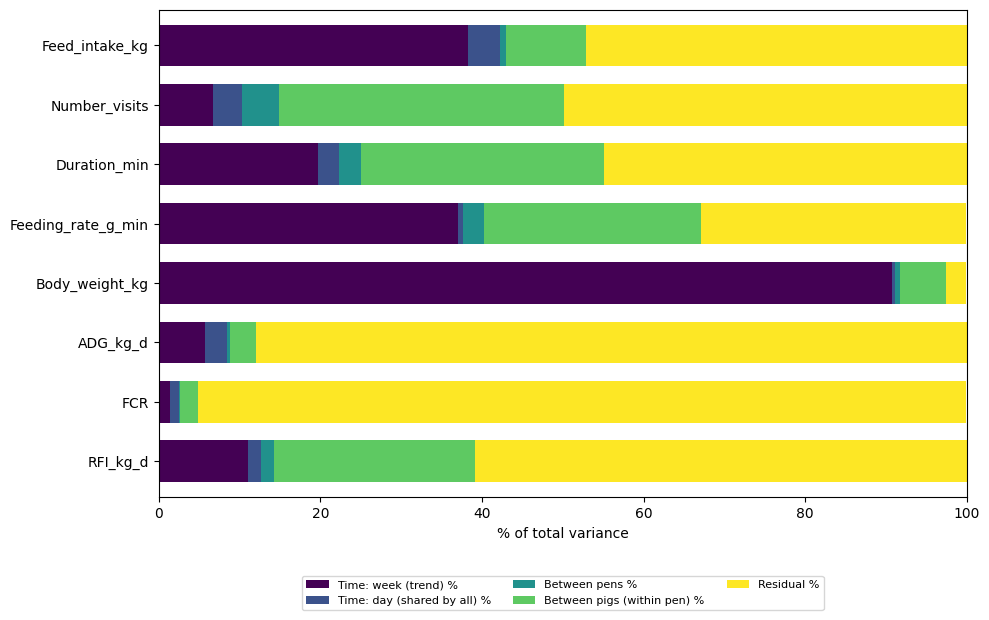

In [21]:
t = variance_table(df, cols)
plot_variance_table(t)

As we can see, Body weight is almost purely explained by trend. This makes sense, since it's expected that pigs will grow every week and in the visual inspection we saw that this growth looks linear. Most variables combine trend with individual pig differences and residual information (variability in the same pig). ADG and FCR variance can be almost fully explained by residual information. 

Whether this residual information is white noise or has some structure will be explored later on

## 3. Is the variability of each variable stable over time?

In [22]:
from utils import weekly_variability, variability_summary, plot_variability

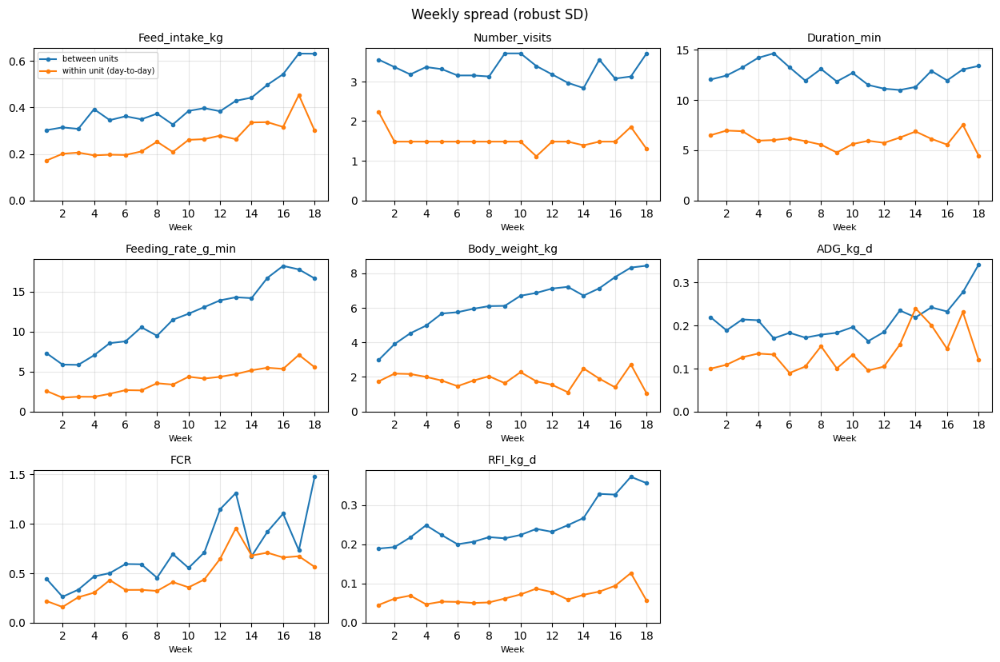

In [23]:
variability_summary(df, cols)
fig = plot_variability(df, cols)

Interpretation:

- Blue: How different are pigs from others every day

- Orange: How different are the observations within the same pig different days

As we can observe, variables with suspected trend, like `Feed_intake_kg`, `Feeding_rate_g_min` or `Body_weight_kg` have increasing variability within different pigs as time passes. The variability of observations of the same pig has a more modest increase.

## 4. Which variables have trend, seasonality, stationarity and age-dependence?

In [24]:
from utils import temporal_properties, temporal_properties_table

In [25]:
temporal_properties_table(df, cols, alpha=0.05)

,level,n_series,trend %,trend (mean),mean slope/day,seasonality %,seasonality (mean),stationarity %,stationarity (mean),age_dependence %,age_dependence (mean)
Feed_intake_kg,animal,118,91.5,1.0,0.010134,19.5,0.0,2.5,0.0,92.4,1.0
Number_visits,animal,118,62.7,1.0,-0.020843,32.2,1.0,24.6,0.0,65.3,1.0
Duration_min,animal,118,85.6,1.0,-0.18795,23.7,0.0,10.2,0.0,86.4,1.0
Feeding_rate_g_min,animal,118,96.6,1.0,0.332529,16.9,1.0,2.5,0.0,95.8,1.0
Body_weight_kg,animal,118,100.0,1.0,0.791528,19.5,0.0,0.0,0.0,97.5,1.0
ADG_kg_d,animal,118,35.6,0.0,-0.000486,28.0,0.0,55.9,1.0,7.6,0.0
FCR,animal,118,91.5,1.0,0.020058,16.1,0.0,18.6,0.0,55.9,1.0
RFI_kg_d,animal,118,37.3,0.0,0.000017,0.0,0.0,15.3,1.0,5.9,0.0


Interpretation:

- First column: Number of different time-series of the variable

- Second column: Percentatge of series that pass the test
- Third column: Whether the mean time series passes the test
- Fourth column: Mean p-value of the test for all time series
- Fifth column: Mean slope per day. Ignore it if trend is not statistically significant.

### Room-level variables: Respiratory score

In [26]:
r = temporal_properties(df, "Respiratory_score", alpha=0.05)

In [27]:
r["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,1.0,0.0,0.0,0.333527,-0.082192
seasonality,1.0,0.0,0.0,0.944768,NaN
stationarity,1.0,100.0,1.0,NaN,NaN
age_dependence,1.0,0.0,0.0,0.496658,NaN


Respiratory score is stationary and does not have trend or seasonality

### Pen-level variables: Water use

In [28]:
r2 = temporal_properties(df, "Water_use_L", alpha=0.05)
r2["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,9.0,88.9,1.0,0.008906,0.10135
seasonality,9.0,22.2,0.0,0.220887,NaN
stationarity,9.0,0.0,0.0,NaN,NaN
age_dependence,9.0,77.8,1.0,0.025896,NaN


Water use seems to have a positive trend. It's logical then to say that it's not stationary. But what if we differenciate it?

In [29]:
pen_day = (df.groupby(["Pen", "Date"], as_index=False)["Water_use_pen_L"].mean()
             .sort_values(["Pen", "Date"]))
pen_day["Water_use_pen_L_diff"] = pen_day.groupby("Pen")["Water_use_pen_L"].diff()
gap = pen_day.groupby("Pen")["Date"].diff().dt.days != 1
pen_day.loc[gap, "Water_use_pen_L_diff"] = np.nan

df_diff = df.merge(pen_day[["Pen", "Date", "Water_use_pen_L_diff"]],
                   on=["Pen", "Date"], how="left")


pig_cols = ["Feed_intake_kg", "Number_visits", "Duration_min", "Feeding_rate_g_min",
            "Body_weight_kg", "ADG_kg_d", "FCR", "RFI_kg_d"]

df_diff = df_diff.sort_values(["Animal_ID", "Date"])
g = df_diff.groupby("Animal_ID")
consecutive = g["Date"].diff().dt.days == 1
for col in pig_cols:
    df_diff[f"{col}_diff"] = g[col].diff().where(consecutive)

In [30]:
temporal_properties(df_diff, "Water_use_pen_L_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,9.0,22.2,1.0,0.048451,-0.030854
seasonality,9.0,11.1,0.0,0.371592,NaN
stationarity,9.0,88.9,1.0,NaN,NaN
age_dependence,9.0,0.0,0.0,0.447442,NaN


The differenciated series seems to be starionary. Whether it has trend is ambigous. The mean time-series has trend but most inidivdual series don't have trend. This means that there are 'outlier pens' that preserve trend while the other pens don't have it.

### Pig-level variables: Feeding behavour

#### Feed intake

In [31]:
r3 = temporal_properties(df, "Feed_intake_kg", alpha=0.05)
r3["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,91.5,1.0,0.000003,0.010134
seasonality,118.0,19.5,0.0,0.636211,NaN
stationarity,118.0,2.5,0.0,NaN,NaN
age_dependence,118.0,92.4,1.0,0.003355,NaN


Feed intake appears to have a positive trend and not stationarity. Let's analize the differenciated series:

In [32]:
temporal_properties(df_diff, "Feed_intake_kg_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,6.8,0.0,0.303136,-0.000244
seasonality,118.0,16.1,0.0,0.551897,NaN
stationarity,118.0,94.9,1.0,NaN,NaN
age_dependence,118.0,0.0,0.0,0.463643,NaN


The differenciated series is stationary and does not have trend

#### Number of visits

In [33]:
r4 = temporal_properties(df, "Number_visits", alpha=0.05)
r4["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,62.7,1.0,0.000000e+00,-0.020843
seasonality,118.0,32.2,1.0,2.542554e-03,NaN
stationarity,118.0,24.6,0.0,NaN,NaN
age_dependence,118.0,65.3,1.0,8.900118e-07,NaN


Number visits appears to have a negative trend and seasonality.  

Seasonality is a weird case: the p-value is extremely low but only 32% of the series appear to have statistical significance. Averaging across pigs removes individual noise, revealing a weak weekly pattern that most pigs share but that is too small to be detected in each one on its own.

In [34]:
temporal_properties(df_diff, "Number_visits_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,12.7,0.0,0.361070,0.000497
seasonality,118.0,26.3,1.0,0.022927,NaN
stationarity,118.0,94.9,1.0,NaN,NaN
age_dependence,118.0,0.0,0.0,0.668404,NaN


The differenciated series apppears to be stationary but preserves seasonality.

#### Feeding duration

In [35]:
r5 = temporal_properties(df, "Duration_min", alpha=0.05)
r5["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,85.6,1.0,1.494511e-07,-0.18795
seasonality,118.0,23.7,0.0,6.038785e-01,NaN
stationarity,118.0,10.2,0.0,NaN,NaN
age_dependence,118.0,86.4,1.0,3.177518e-03,NaN


Feeding duration appears to have a very significant negative trend. Let's see what happens when we differenciate it.

In [36]:
temporal_properties(df_diff, "Duration_min_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,3.4,0.0,0.300351,-0.001866
seasonality,118.0,18.6,0.0,0.633459,NaN
stationarity,118.0,99.2,1.0,NaN,NaN
age_dependence,118.0,0.0,0.0,0.738188,NaN


The differenciated series appears to be stationary

#### Feeding rate

In [37]:
r6 = temporal_properties(df, "Feeding_rate_g_min", alpha=0.05)
r6["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,96.6,1.0,4.440892e-16,0.332529
seasonality,118.0,16.9,1.0,4.155714e-02,NaN
stationarity,118.0,2.5,0.0,NaN,NaN
age_dependence,118.0,95.8,1.0,1.067315e-02,NaN


Feeding rate appears to have a very significant positive trend, as well as seasonality similar to the number of visits: only a few series make seasonality statistically significant on average

Let's see what happens when we differenciate the series

In [38]:
temporal_properties(df_diff, "Feeding_rate_g_min_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,7.6,0.0,0.405034,0.003011
seasonality,118.0,11.0,0.0,0.094469,NaN
stationarity,118.0,95.8,1.0,NaN,NaN
age_dependence,118.0,0.0,0.0,0.348019,NaN


The differencited series appears to be stationary

#### Body weight

In [39]:
r7 = temporal_properties(df, "Body_weight_kg", alpha=0.05)
r7["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,100.0,1.0,7.726196e-08,0.791528
seasonality,118.0,19.5,0.0,5.824110e-01,NaN
stationarity,118.0,0.0,0.0,NaN,NaN
age_dependence,118.0,97.5,1.0,1.289807e-05,NaN


Body weight appears to have a very significant positive trend. Let's see what happens when we differenciate it

In [40]:
temporal_properties(df_diff, "Body_weight_kg_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,16.9,0.0,0.215418,-0.00084
seasonality,118.0,27.1,0.0,0.604034,NaN
stationarity,118.0,83.9,1.0,NaN,NaN
age_dependence,118.0,9.3,0.0,0.525196,NaN


The differenciated series appears to be stationary

#### ADG

In [41]:
r8 = temporal_properties(df, "ADG_kg_d", alpha=0.05)
r8["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,35.6,0.0,0.462416,-0.000486
seasonality,118.0,28.0,0.0,0.079386,NaN
stationarity,118.0,55.9,1.0,NaN,NaN
age_dependence,118.0,7.6,0.0,0.765016,NaN


ADG appears to be already stationary. This makes sense, since it's computed with Body weight differences

### FCR

In [42]:
r9 = temporal_properties(df_diff, "FCR", alpha=0.05)
r9["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,91.5,1.0,8.307748e-08,0.020058
seasonality,118.0,16.1,0.0,3.266089e-01,NaN
stationarity,118.0,18.6,0.0,NaN,NaN
age_dependence,118.0,55.9,1.0,8.056772e-03,NaN


FCR appears to have a positive trend. Let's see what happens when we differenciate it

In [43]:
temporal_properties(df_diff, "FCR_diff")["summary"]

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,117.0,10.3,0.0,0.751341,0.000165
seasonality,117.0,28.2,0.0,0.542077,NaN
stationarity,117.0,88.0,1.0,NaN,NaN
age_dependence,117.0,0.0,0.0,0.916113,NaN


The differenciated series appears to be stationary.

### RFI

In [44]:
r10 = temporal_properties(df, "RFI_kg_d", alpha=0.05)
r10["summary"] 

,n_series,pct_series,mean_series_pass,mean_series_p,mean_slope_per_day
trend,118.0,37.3,0.0,0.988780,0.000017
seasonality,118.0,0.0,0.0,0.878970,NaN
stationarity,118.0,15.3,1.0,NaN,NaN
age_dependence,118.0,5.9,0.0,0.984674,NaN


   RFI is stationary on average but not in most individual pigs (15%). Individual drifts in opposite directions cancel out in the mean series, and ADF has low power on short, highly persistent series, so the mean series result (ADF p = 0.029) should be read with caution.

## 5. Are observations of each variable dependent on previous observations? How much memory do they have (ACF/PACF)

In [45]:
from utils import acf_pacf_panel, plot_acf_pacf

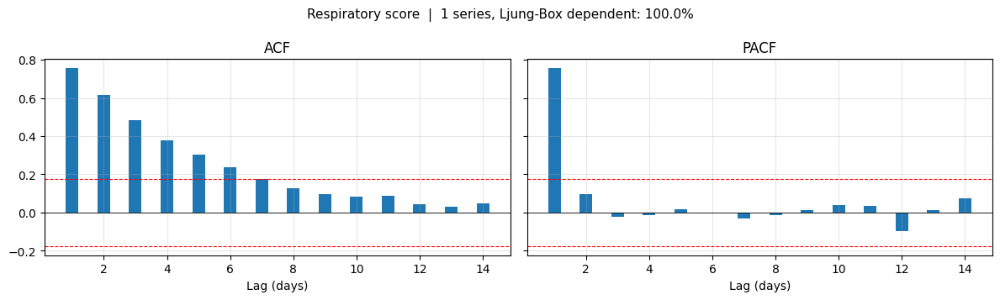

In [46]:
res_rs = acf_pacf_panel(df, "Respiratory_score")
plot_acf_pacf(res_rs, "Respiratory score");


An AR(1) relation can be observed for respiratory score. Meaning that an observation depends on a previous observation

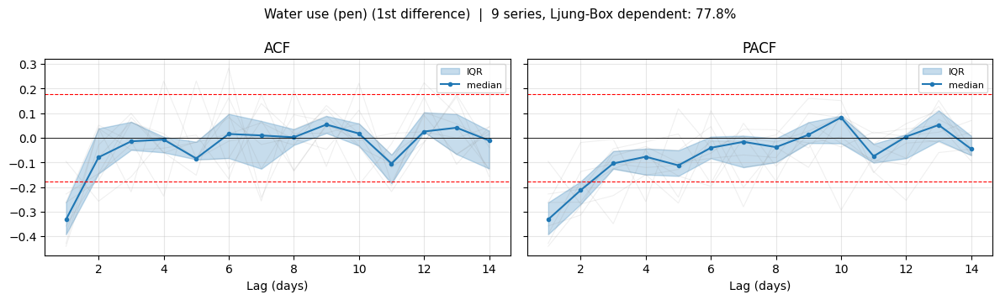

In [47]:
res = acf_pacf_panel(df, "Water_use_pen_L", diff=True)
plot_acf_pacf(res, "Water use (pen)",);

This case is closer to ARIMA(0, 1, 1), since once differencied, ACF only has the first value as significant and PACF decays exponentially, averaged across pens.

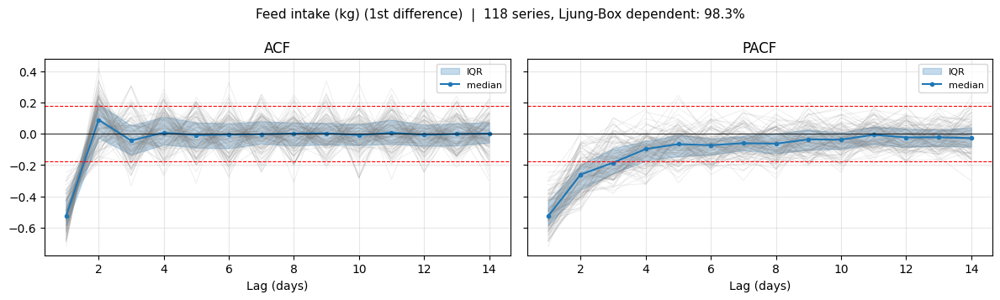

In [48]:
res = acf_pacf_panel(df, "Feed_intake_kg", diff=True)
plot_acf_pacf(res, "Feed intake (kg)",);

This case looks like ARIMA(0, 1, 1) also. 

Right now, we won't explore other variables. But we could infere than the ones related to feeding behavours will share similar behavours

## 6. Which time series present discontinuity?

By looking at the graphs from the first section, we note that Body weight appears to have discontinuity in some pigs. This could be due to fails in the mesuring system and we should investigate this further.

## 7. Do the series of different pigs/pens share common temporal patterns (farm-wide day effects, synchrony) or does each one evolve independently?

In [49]:
import seaborn as sns
from utils import synchrony

<Axes: xlabel='Pen', ylabel='Pen'>

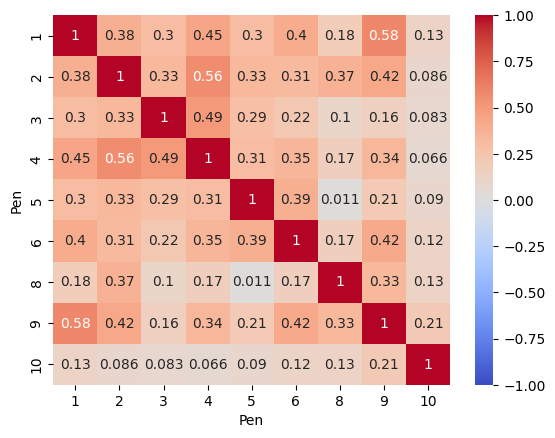

In [50]:
pw = df.groupby(["Date", "Pen"])["Water_use_pen_L"].mean().unstack().diff()
pw = pw.drop(columns=7)           
sns.heatmap(pw.corr(), annot=True, vmin=-1, vmax=1, cmap="coolwarm")

The heatmap shows the correlation between pens of the *daily change* in water use (first difference, pen 7 excluded due to its 78% missingness). Differencing removes the age-related trend shared by all pens, so the correlations reflect true day-to-day co-movement rather than the fact that all pigs drink more as they grow.

- All correlations are positive (mean ≈ 0.27, typical values 0.2–0.4), so there is a **farm-wide day effect**, but a weak one: with r ≈ 0.3, two pens share only ~9% of their daily variance (r²). Most day-to-day variation is pen-specific.
- Pens 1, 2, 4 and 9 are the most synchronized (r up to 0.58, e.g. 1–9 and 2–4).
- Pen 10 evolves almost independently (r < 0.21 with every pen), and pen 8 is nearly uncorrelated with pen 5 (r ≈ 0.01).

Caveats: differencing amplifies measurement noise, so these values are a lower bound of the true synchrony. Also, since water use is computed from the next day's reading (see notebook 01), part of the shared signal could be a common measurement artifact rather than a biological effect. Finally, this only captures same-day synchrony (lag 0).

In [51]:
cols = ["Feed_intake_kg", "Number_visits", "Duration_min",
        "Feeding_rate_g_min", "Body_weight_kg"]
pd.DataFrame({c: synchrony(df, c) for c in cols}).T.round(3)

,corr same pen,corr diff pen,median R² vs farm,PC1 var share
Feed_intake_kg,0.220,0.186,0.197,0.207
Number_visits,0.132,0.098,0.093,0.151
Duration_min,0.150,0.139,0.150,0.176
Feeding_rate_g_min,0.077,0.040,0.033,0.109
Body_weight_kg,0.335,0.227,0.273,0.392


For each variable, series are detrended (linear fit per pig) and then compared across pigs. The table reports:

- `corr same pen` / `corr diff pen`: mean correlation between pigs of the same pen vs. different pens. A clear gap indicates a **pen effect**; similar values mean that what is shared is farm-wide (or nothing).
- `median R² vs farm`: share of a pig's variance explained by the mean of the rest of the farm. High values mean pigs follow a common daily pattern.
- `PC1 var share`: variance explained by the first principal component of all series, a measure of how much a single common factor drives the whole farm.

Results: [Feed intake / visits / ... ] show [strong / weak] synchrony (median R² = [..], PC1 = [..]%). Same-pen correlation ([..]) is [higher than / similar to] different-pen correlation ([..]), so [there is / there is not] a pen effect beyond the farm-wide one. [Body weight] is [more / less] synchronized than the feeding variables, which is expected / surprising because [...].

**Implication:** [If farm-wide effect is relevant] a farm-day effect should be removed (e.g. subtracting the daily farm mean) before comparing pigs or building references. [If it is weak] each pig can be treated as an independent series and compared against its own history.